## Configs

In [2]:
import os, sys, re, json, math, time, random, inspect, warnings
from pathlib import Path

# model configs
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
CHAT = True
QUANT = "fp32"   # "4bit" | "8bit" | "fp16" | "bf16" | "fp32"
COMPUTE_DTYPE = None

# data / output configs
DATA_PATH = Path("/kaggle/input/datasets/amallick0507/probad")
SPLIT = "test"
N_ITEMS = int(os.environ.get("PROBAD_N", "0")) or None # None = all items; to test on small set
RESULTS_ROOT = Path("/kaggle/working/")
RUN_NAME = MODEL_ID.split("/")[-1] + ("" if N_ITEMS is None else f"_smoke{N_ITEMS}")
OUT = RESULTS_ROOT / RUN_NAME
RAW, FIG, TAB = OUT / "raw", OUT / "figs", OUT / "tables"

# run config
RUN_EXPERIMENTS = True # False = only analysis by reading data dfs
RUN = {"x1": True, "x2": True, "x3": True, "x4": True, "x5": True,
       "x6": True, "x7": True, "x8": True}
LANGS = ["en", "bn"]
RENDERS = ["romanised", "bengali", "gloss", "gloss_only"] # x6
ORDERS = "swap" # "swap" = seed 0 + swapped order(s); "seed0" = ordinary order only
X8_CONDITIONS = ["C1a", "C1b"] # C0 default and always runs
SYSTEM_PROMPTS_BN = {
    "C1a": "তুমি বাংলায় বড় হওয়া একজন বাঙালি, বাংলা তোমার মাতৃভাষা।",
    "C1b": ("তুমি কলকাতার এক মধ্যবিত্ত পরিবারে বড় হওয়া একজন বাঙালি, বাংলা তোমার মাতৃভাষা। "
            "গ্রামবাংলায় আর বাংলাদেশেও তোমার আত্মীয়স্বজন আছেন। বাড়িতে তুমি বাংলায় কথা বলো, "
            "কলেজে আর কাজের জায়গায় ইংরেজিতে, আর প্রায়ই দুই ভাষা মিশিয়ে কথা বলো। "
            "দাদু-ঠাকুমার কাছে, স্কুলে আর রোজকার কথাবার্তায় শুনে শুনে তুমি অনেক বাংলা প্রবাদ জানো। "
            "তুমি জানো, মানুষ প্রবাদ বলে কোনো পরিস্থিতি নিয়ে মন্তব্য করতে, ঠাট্টা করতে, সাবধান করতে "
            "কিংবা উপদেশ দিতে; প্রবাদে যে জিনিসগুলোর কথা আছে, সেগুলোর আক্ষরিক অর্থে কিছু বলতে নয়। "
            "যে কথোপকথনগুলো তুমি পড়বে, তাতে বাঙালি বন্ধুবান্ধব, পরিবারের লোকজন, সহপাঠী আর সহকর্মীরা "
            "রোজকার জীবনের নানা বিষয়ে কথা বলছে।"),
}
SMOKE_ITEMS = 3 # items per condition in the pre-flight check

# analysis
MAIN = "acc" # metric in the plots: "acc" | "acc_db" | "acc_seed0" | "acc_strict"
STRICT_MASS = True   # stop the analysis if the letter mass looks broken
COMPARE_DIRS = [] # extra result folders from other models (each with a raw/ folder) for Section K
INCLUDE_SMOKE_RUNS = False # include *_smoke runs in the cross-model comparison

## Setup

In [3]:
import subprocess
REPO_USER, REPO_NAME = "AnikMallick", "bn-proverbs-in-context"
REPO_DIR = (Path("/kaggle/working") / REPO_NAME)

import base64
from kaggle_secrets import UserSecretsClient
secrets = UserSecretsClient()
if not REPO_DIR.exists():
    token = secrets.get_secret("GITHUB_TOKEN")
    auth = base64.b64encode(f"{REPO_USER}:{token}".encode()).decode()
    try:
        subprocess.run(["git", "-c", f"http.https://github.com/.extraheader=AUTHORIZATION: basic {auth}",
                        "clone", f"https://github.com/{REPO_USER}/{REPO_NAME}.git", str(REPO_DIR)], check=True)
    finally:
        del token, auth
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_DIR)], check=True)
try:
    os.environ["HF_TOKEN"] = secrets.get_secret("HF_TOKEN")
except Exception:
    print("No HF_TOKEN secret")
if RUN_EXPERIMENTS and QUANT in ("4bit", "8bit"):
    try:
        import bitsandbytes  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bitsandbytes"], check=True)

In [4]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm
from tqdm.auto import tqdm
from IPython.display import display, Markdown

import probad.builder as exp
from probad.schema import TestItem, validate_items
from probad.utils import print_div

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
for d in (RAW, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
print("results ->", OUT)

results -> /kaggle/working/Qwen2.5-1.5B-Instruct


## 1. Data

In [5]:
def load_split(name):
    return list(TestItem.load_items(DATA_PATH / f"{name}.jsonl"))

_items = load_split(SPLIT)
stop_path = DATA_PATH / "stopwords-bn.json"
BN_STOPWORDS = (frozenset(w.strip() for w in json.loads(stop_path.read_text(encoding="utf-8-sig")))
                if stop_path.exists() else frozenset())
print_div(SPLIT)
for issue in validate_items(_items, BN_STOPWORDS):
    print(issue)

ITEMS_ALL = [it.model_dump() for it in _items]
ITEMS = ITEMS_ALL[:N_ITEMS] if N_ITEMS else ITEMS_ALL
ITEM_BY_ID = {it["item_id"]: it for it in ITEMS_ALL}
print(f"{len(ITEMS)} items, {len({it['proverb']['proverb_id'] for it in ITEMS})} proverbs ({SPLIT})")

==============================================> test <==============================================
[WARNING] prv_088_1: en.correct_echoes_gloss: correct option reuses many literal-gloss words
[WARNING] prv_088_2: en.correct_echoes_gloss: correct option reuses many literal-gloss words
600 items, 200 proverbs (test)


## 2. Model

In [6]:
def load_model(model_id, quant=QUANT, compute=COMPUTE_DTYPE):
    import torch, transformers
    from transformers import AutoTokenizer, AutoModelForCausalLM
    cuda = torch.cuda.is_available()
    if compute is None:
        compute = "bf16" if cuda and torch.cuda.get_device_capability()[0] >= 8 else ("fp16" if cuda else "fp32")
    dt = {"fp16": torch.float16, "bf16": torch.bfloat16, "fp32": torch.float32}
    dtype_kw = "dtype" if tuple(int(x) for x in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
    kw = {"device_map": "auto"} if cuda else {}
    if quant in ("4bit", "8bit"):
        from transformers import BitsAndBytesConfig
        kw["quantization_config"] = (BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                        bnb_4bit_compute_dtype=dt[compute], bnb_4bit_use_double_quant=True)
                                     if quant == "4bit" else BitsAndBytesConfig(load_in_8bit=True))
        kw[dtype_kw] = dt[compute]
    else:
        kw[dtype_kw] = dt[quant]
    tok = AutoTokenizer.from_pretrained(model_id)
    try:
        model = AutoModelForCausalLM.from_pretrained(model_id, **kw)
    except (ValueError, KeyError) as e:          # e.g. Gemma 3 4B is registered as an image-text-to-text model
        from transformers import AutoModelForImageTextToText
        print("AutoModelForCausalLM failed:", str(e)[:150], "\n-> loading with AutoModelForImageTextToText")
        model = AutoModelForImageTextToText.from_pretrained(model_id, **kw)
    return tok, model.eval()

if RUN_EXPERIMENTS:
    import torch, transformers
    tok, model = load_model(MODEL_ID)
    DEVICE = next(model.parameters()).device
    print(f"{MODEL_ID} | chat={CHAT} | quant={QUANT} | device={DEVICE} | vocab={len(tok)} | "
          f"torch {torch.__version__} | transformers {transformers.__version__}")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct | chat=True | quant=fp32 | device=cuda:0 | vocab=151665 | torch 2.11.0+cu130 | transformers 5.20.2


## 3. Scoring

In [7]:
KEYS = ("correct", "literal", "plausible", "none")
_norm = lambda s: re.sub(r"\s+", " ", str(s)).strip().strip("।.!?\"'“”‘’ ").lower()

def option_lines(prompt):
    """{letter: text} for the options of the last question in an own-format prompt ("A. ..." lines)."""
    block = prompt[prompt.rfind("\n\n"):] if "\n\n" in prompt else prompt
    return {m.group(1): m.group(2).strip() for m in re.finditer(r"^([ABC])\. (.*)$", block, flags=re.M)}

def option_key(text, item):
    """Which option a text is: exact match first, then containment; anything unmatched is 'None of these'."""
    cands = {"correct": [item["proverb"].get("meaning", {}).get(l) for l in ("en", "bn")], "literal": [], "plausible": []}
    for l in ("en", "bn"):
        o = item.get(l, {}).get("options", {})
        for k in ("correct", "literal", "plausible"):
            cands[k].append(o.get(k))
    t = _norm(text)
    for k, texts in cands.items():
        if any(c and _norm(c) == t for c in texts):
            return k
    for k, texts in cands.items():
        for c in texts:
            c = _norm(c) if c else ""
            if c and min(len(c), len(t)) >= 12 and (c in t or t in c):
                return k
    return "none"

if RUN_EXPERIMENTS:
    def to_model_text(prompt, system=None):
        """Base model: system prompt on top as plain text. Chat model: chat template, then the prompt's own
        answer cue ("Answer:" / "উত্তর:") at the start of the reply, so the next token is the letter."""
        if not CHAT:
            return f"{system}\n\n{prompt}" if system else prompt
        msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
        try:
            text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        except Exception: # templates without a system role: merge it into the user turn
            user = f"{system}\n\n{prompt}" if system else prompt
            text = tok.apply_chat_template([{"role": "user", "content": user}], tokenize=False, add_generation_prompt=True)
        return text + prompt.rstrip().rsplit("\n", 1)[-1]

    def _letter_id(L):
        ids = tok.encode(" " + L, add_special_tokens=False)
        if len(ids) > 1 and tok.decode(ids[:1]).strip() == "":   # SentencePiece may split off a bare space
            ids = ids[1:]
        return ids[0]

    LETTER_ID = {L: _letter_id(L) for L in "ABCabc"}

    def _probe_logits_kw():
        enc = tok("probe", return_tensors="pt").to(DEVICE)
        for kw in ({"logits_to_keep": 1}, {"num_logits_to_keep": 1}):
            try:
                with torch.inference_mode():
                    out = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], use_cache=False, **kw)
                if out.logits.shape[1] == 1:
                    return kw
            except (TypeError, ValueError):
                pass
        return {}

    LOGITS_KW = _probe_logits_kw()

    @torch.inference_mode()
    def next_logprobs(text):
        enc = tok(text, return_tensors="pt", add_special_tokens=not CHAT).to(DEVICE)
        out = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], use_cache=False, **LOGITS_KW)
        lp = torch.log_softmax(out.logits[0, -1].float(), dim=-1)
        if torch.isnan(lp).any():
            raise FloatingPointError("NaN log-probs: the model overflowed. Set COMPUTE_DTYPE = 'fp32' and reload.")
        return lp

    def score_prompt(item, prompt, gold, system=None):
        lines = option_lines(prompt)
        if not lines:
            raise ValueError(f"no 'A. ...' option lines found in the prompt for {item['item_id']}")
        letters = list(lines)
        gold_U = str(gold).strip().upper()
        if gold_U not in lines:
            raise ValueError(f"gold {gold!r} is not among the shown letters {letters} ({item['item_id']})")
        lp = next_logprobs(to_model_text(prompt, system))
        raw = {L: lp[LETTER_ID[L]].item() for L in letters}
        mass = sum(math.exp(v) for v in raw.values())
        pred_U = max(raw, key=raw.get)
        keys = {L: option_key(lines[L], item) for L in letters}
        top = int(lp.argmax())
        row = {"gold": gold_U.lower(), "pred": pred_U.lower(), "correct": pred_U == gold_U, "n_opts": len(letters),
               "margin": raw[gold_U] - max(v for L, v in raw.items() if L != gold_U), "letter_mass": mass,
               "top_token": tok.decode([top]), "top_is_letter": top in {LETTER_ID[L] for L in letters},
               "gold_key": keys[gold_U], "pred_key": keys[pred_U]}
        for L in "ABC":
            row[f"p_{L.lower()}"] = math.exp(raw[L]) / mass if L in raw else np.nan
            row[f"key_{L.lower()}"] = keys.get(L)
        for k in KEYS:
            row[f"p_{k}"] = sum(row[f"p_{L.lower()}"] for L in letters if keys[L] == k) if k in keys.values() else np.nan
        return row

    CACHE = {}
    def score_cached(item, prompt, gold, system):
        """Identical inputs are scored once (x8 C0 = x1, x6 romanised = x1 en)."""
        key = (system or "", prompt, str(gold).lower())
        if key not in CACHE:
            CACHE[key] = score_prompt(item, prompt, gold, system)
        return CACHE[key]

## 4. Experiments and option orders

In [8]:
_SIG = {}
def accepts(fn, name):
    if (fn, name) not in _SIG:
        try:
            ps = inspect.signature(fn).parameters
            _SIG[(fn, name)] = name in ps or any(p.kind == p.VAR_KEYWORD for p in ps.values())
        except (TypeError, ValueError):
            _SIG[(fn, name)] = True
    return _SIG[(fn, name)]

def english_system_prompts():
    en = dict(getattr(exp, "SYSTEM_PROMPTS", {}) or {})
    for c in X8_CONDITIONS:
        if not en.get(c):
            en[c] = exp.x8_system_prompt(ITEMS[0], condition=c)[0]
    return en

def U(exp_name, label, make, system=None, prompt_lang=None, condition=None, **kw):
    return dict(exp=exp_name, label=label, make=make, kw=kw, system=system, prompt_lang=prompt_lang, condition=condition)

def make_units():
    units = []
    for e, fn in [("x1", "x1_correct_vs_literal"), ("x2", "x2_negative"), ("x3", "x3_none_of_these"),
                  ("x4", "x4_meaning_no_context"), ("x5", "x5_three_way"), ("x7", "x7_no_question")]:
        if RUN.get(e):
            units += [U(e, f"{e}_{l}", getattr(exp, fn), lang=l) for l in LANGS]
    if RUN.get("x6"):
        units += [U("x6", f"x6_{r}", exp.x6_render, render=r) for r in RENDERS]
    if RUN.get("x8"):
        sys_en = english_system_prompts()
        for conv in LANGS:
            units.append(U("x8", f"x8_{conv}_C0", exp.x1_correct_vs_literal, prompt_lang="none", condition="C0", lang=conv))
            for c in X8_CONDITIONS:
                units.append(U("x8", f"x8_{conv}_{c}", exp.x1_correct_vs_literal, system=sys_en[c],
                               prompt_lang="en", condition=c, lang=conv))
            for c in X8_CONDITIONS:
                if c in SYSTEM_PROMPTS_BN:
                    units.append(U("x8", f"x8_{conv}_pbn_{c}", exp.x1_correct_vs_literal, system=SYSTEM_PROMPTS_BN[c],
                                   prompt_lang="bn", condition=c, lang=conv))
    return units

def build(unit, item, seed):
    """-> [(label, system, prompt, gold)]; empty if the builder returns None for this item."""
    kw = dict(unit["kw"])
    if accepts(unit["make"], "seed"):
        kw["seed"] = seed
    elif seed != 0:
        return []
    out = unit["make"](item, **kw)
    if out is None:
        return []
    if isinstance(out, dict):
        variants = list(out.items())
    elif isinstance(out, (list, tuple)) and out and isinstance(out[0], (list, tuple)):
        variants = [(str(i), t) for i, t in enumerate(out)]      # several prompts without names
    else:
        variants = [(None, out)]
    res = []
    for var, t in variants:
        if t is None:
            continue
        t = tuple(t)
        if len(t) == 2:
            system, prompt, gold = None, t[0], t[1]
        elif len(t) == 3: # (prompt, gold, options) or (system, prompt, gold)
            system, prompt, gold = (None, t[0], t[1]) if isinstance(t[2], (list, tuple)) else t
        else: # (system, prompt, gold, options)
            system, prompt, gold = t[0], t[1], t[2]
        label = unit["label"] if var is None else f"{unit['label']}_{var}"
        res.append((label, unit["system"] if unit["system"] is not None else system, prompt, gold))
    return res

_SEEDS = {}
def order_seeds(unit, item):
    """Seed 0 plus the first seeds that put the gold letter in each other position (see the markdown above)."""
    key = (unit["make"].__name__, tuple(sorted(unit["kw"].items())), item["item_id"])
    if key in _SEEDS:
        return _SEEDS[key]
    first = build(unit, item, 0)
    seeds = [0] if first else []
    if first and ORDERS == "swap" and accepts(unit["make"], "seed"):
        _, _, p0, g0 = first[0]
        n = max(len(option_lines(p0)), 2)
        golds, prompts = {str(g0).lower()}, {p0}
        for s in range(1, 300):
            b = build(unit, item, s)
            if not b:
                break
            if str(b[0][3]).lower() not in golds:
                seeds.append(s); golds.add(str(b[0][3]).lower()); prompts.add(b[0][2])
            if len(golds) >= n:
                break
        if len(seeds) == 1: # the gold letter never moves (x3): swap the other options instead
            for s in range(1, 300):
                b = build(unit, item, s)
                if b and b[0][2] not in prompts:
                    seeds.append(s)
                    break
    _SEEDS[key] = seeds
    return seeds

def jobs_for(unit, items):
    return [(it, label, system, prompt, gold, s, order)
            for it in items for order, s in enumerate(order_seeds(unit, it))
            for label, system, prompt, gold in build(unit, it, s)]

def row_meta(unit, it, label, seed, order):
    kw = unit["kw"]
    render = kw.get("render") or (label.rsplit("_", 1)[-1] if unit["exp"] == "x9" else None)
    m = it.get("meta", {}) or {}
    return {"model": MODEL_ID, "run": RUN_NAME, "exp": unit["exp"], "label": label, "item_id": it["item_id"],
            "proverb_id": it["proverb"]["proverb_id"], "figurative": it["proverb"].get("figurative"),
            "split": m.get("split"), "subsets": "|".join(m.get("subsets") or []),
            "conv_lang": kw.get("lang", "en"), "render": render, "prompt_lang": unit["prompt_lang"],
            "condition": unit["condition"], "seed": seed, "order": order}

UNITS = make_units()
print(f"{len(UNITS)} conditions:", ", ".join(u["label"] for u in UNITS))

26 conditions: x1_en, x1_bn, x2_en, x2_bn, x3_en, x3_bn, x4_en, x4_bn, x5_en, x5_bn, x7_en, x7_bn, x6_romanised, x6_bengali, x6_gloss, x6_gloss_only, x8_en_C0, x8_en_C1a, x8_en_C1b, x8_en_pbn_C1a, x8_en_pbn_C1b, x8_bn_C0, x8_bn_C1a, x8_bn_C1b, x8_bn_pbn_C1a, x8_bn_pbn_C1b


## 5. Pre-flight check

In [9]:
EXPECTED_GOLD = {"x2": "literal", "x3": "none"}

if RUN_EXPERIMENTS:
    t0, rows = time.time(), []
    smoke = ITEMS[:SMOKE_ITEMS]
    for u in list(UNITS):
        try:
            for it, label, system, prompt, gold, s, order in jobs_for(u, smoke):
                rows.append({**row_meta(u, it, label, s, order), **score_prompt(it, prompt, gold, system)})
        except Exception as e: # a builder that does not fit: drop that condition, keep the rest
            print(f"SKIPPING {u['label']}: {type(e).__name__}: {e}")
            UNITS.remove(u)
    sec_per = (time.time() - t0) / max(len(rows), 1)
    SM = pd.DataFrame(rows)
    chk = SM.groupby("label", sort=False).agg(
        rows=("item_id", "size"), orders=("order", "nunique"),
        gold_letters=("gold", lambda s: "".join(sorted(set(s)))),
        gold_key=("gold_key", lambda s: s.mode().iat[0]),
        letter_mass=("letter_mass", "median"), top_is_letter=("top_is_letter", "mean")).reset_index()
    chk["expected"] = chk["label"].str.split("_").str[0].map(lambda e: EXPECTED_GOLD.get(e, "correct"))
    chk["ok"] = (chk["gold_key"] == chk["expected"]) & (chk["letter_mass"] > 0.05)
    display(chk.round(3))
    if (chk["letter_mass"] < 0.05).any():
        print("WARNING: letter mass < 0.05 for some conditions. The model is not answering with a letter there;"
              " check CHAT and look at 'top_token' in SM before running everything.")
    if ORDERS == "swap" and (chk["orders"] < 2).any():
        print("WARNING: only one option order for:", ", ".join(chk.loc[chk["orders"] < 2, "label"]),
              "-> that builder ignores `seed`, so its options are never swapped.")
    if (chk["gold_key"] != chk["expected"]).any():
        print("WARNING: the gold option is not the expected one for some conditions; check option_key().")
    ex_label = next((l for l in ("x1_bn", "x1_en") if l in set(SM["label"])), SM["label"].iloc[0])
    ex_u = next(u for u in UNITS if u["label"] == ex_label)
    for it, label, system, prompt, gold, s, order in jobs_for(ex_u, smoke[:1]):
        print(f"\n--- {label} | order {order} (seed {s}) | gold {gold} ---\n{to_model_text(prompt, system)[-700:]}")


    PLAN = {u["label"]: jobs_for(u, ITEMS) for u in UNITS}
    unique = len({(sy or "", p, str(g).lower()) for u in UNITS for _, _, sy, p, g, _, _ in PLAN[u["label"]]})
    print(f"\n{sum(len(v) for v in PLAN.values())} scorings planned; {len(UNITS)} conditions still to run "
          f"({unique} unique prompts); ~{sec_per:.2f} s per prompt -> about {unique * sec_per / 3600:.1f} h")

,label,rows,orders,gold_letters,gold_key,letter_mass,top_is_letter,expected,ok
0,x1_en,6,2,ab,correct,0.935,1.0,correct,True
1,x1_bn,6,2,ab,correct,0.945,1.0,correct,True
2,x2_en,6,2,ab,literal,0.880,1.0,literal,True
3,x2_bn,6,2,ab,literal,0.952,1.0,literal,True
4,x3_en,6,2,c,none,0.991,1.0,none,True
5,x3_bn,6,2,c,none,0.988,1.0,none,True
6,x4_en,6,2,ab,correct,0.924,1.0,correct,True
7,x4_bn,6,2,ab,correct,0.951,1.0,correct,True
8,x5_en,9,3,abc,correct,0.985,1.0,correct,True
9,x5_bn,9,3,abc,correct,0.986,1.0,correct,True



--- x1_bn | order 0 (seed 0) | gold a ---
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
রিনা: শুনেছ, পিন্টু শেয়ারের লাভের টাকা পুরোটাই আবার বাজারে ঢেলেছে, দ্বিগুণ করার আশায়?
সঞ্জয়: আর আজ সকালেই বাজার পড়ে গেল, সব শেষ। অতি লোভে তাঁতি নষ্ট।

প্রশ্ন: সঞ্জয় কী বোঝাতে চাইছে?
A. আরও লাভের লোভ করতে গিয়েই পিন্টু নিজের সব খুইয়েছে।
B. বেশি চাওয়ার জন্য একজন কাপড় বোনার কারিগর সর্বস্ব হারিয়েছিল।
উত্তর:<|im_end|>
<|im_start|>assistant
উত্তর:

--- x1_bn | order 1 (seed 2) | gold b ---
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
রিনা: শুনেছ, পিন্টু শেয়ারের লাভের টাকা পুরোটাই আবার বাজারে ঢেলেছে, দ্বিগুণ করার আশায়?
সঞ্জয়: আর আজ সকালেই বাজার পড়ে গেল, সব শেষ। অতি লোভে তাঁতি নষ্ট।

প্রশ্ন: সঞ্জয় কী বোঝাতে চাইছে?
A. বেশি চাওয়ার জন্য একজন কাপড় বোনার কারিগর সর্বস্ব হারিয়েছিল।
B. আরও লাভের লোভ করতে গিয়েই পিন্টু নিজের সব খুইয়েছে।
উত্তর:<|im_end|>
<|im_st

## 6. Run

In [10]:
if RUN_EXPERIMENTS:
    run_info = {"model": MODEL_ID, "chat": CHAT, "quant": QUANT, "compute_dtype": COMPUTE_DTYPE, "orders": ORDERS,
                "split": SPLIT, "n_items": len(ITEMS), "started": time.strftime("%Y-%m-%d %H:%M:%S"), "conditions": {}}
    for n_done, u in enumerate(UNITS, 1):
        path = RAW / f"{u['label']}.csv"
        t0, rows = time.time(), []
        jobs = PLAN[u["label"]] if "PLAN" in globals() else jobs_for(u, ITEMS)
        for it, label, system, prompt, gold, s, order in tqdm(jobs, desc=u["label"], leave=False):
            rows.append({**row_meta(u, it, label, s, order), **score_cached(it, prompt, gold, system)})
        df = pd.DataFrame(rows)
        if df.empty:
            run_info["conditions"][u["label"]] = "no items"
            print(f"[{n_done}/{len(UNITS)}] {u['label']}: no items for this condition, nothing saved")
            continue
        tmp = path.with_suffix(".tmp")
        df.to_csv(tmp, index=False)
        tmp.replace(path)
        run_info["conditions"][u["label"]] = f"{len(df)} rows in {time.time() - t0:.0f}s"
        print(f"[{n_done}/{len(UNITS)}] {u['label']}: {len(df)} rows in {(time.time() - t0) / 60:.1f} min, "
              f"accuracy {df['correct'].mean():.3f}, letter mass {df['letter_mass'].median():.2f}")
    run_info["finished"] = time.strftime("%Y-%m-%d %H:%M:%S")
    (OUT / "run_info.json").write_text(json.dumps(run_info, indent=2, ensure_ascii=False))
    print("done ->", RAW)

x1_en:   0%|          | 0/1200 [00:00<?, ?it/s]

[1/26] x1_en: 1200 rows in 2.0 min, accuracy 0.878, letter mass 0.94


x1_bn:   0%|          | 0/1200 [00:00<?, ?it/s]

[2/26] x1_bn: 1200 rows in 6.3 min, accuracy 0.517, letter mass 0.93


x2_en:   0%|          | 0/1200 [00:00<?, ?it/s]

[3/26] x2_en: 1200 rows in 2.0 min, accuracy 0.699, letter mass 0.88


... (38 outputs left out)

x8_bn_pbn_C1a:   0%|          | 0/1200 [00:00<?, ?it/s]

[25/26] x8_bn_pbn_C1a: 1200 rows in 7.2 min, accuracy 0.563, letter mass 0.89


x8_bn_pbn_C1b:   0%|          | 0/1200 [00:00<?, ?it/s]

[26/26] x8_bn_pbn_C1b: 1200 rows in 16.9 min, accuracy 0.562, letter mass 0.87
done -> /kaggle/working/Qwen2.5-1.5B-Instruct/raw


## 7. Analysis: load and check
This section reads `raw/*.csv` from disk.

| metric | meaning |
|---|---|
| `acc_seed0` | ordinary order only, comparable to the earlier single-order runs |
| `acc` | mean over option orders, i.e. expected accuracy if the order were random; **used in the plots** (`MAIN`) |
| `acc_strict` | right in every order |
| `acc_db` | debiased: the option with the highest probability averaged over orders |
| `consistent` | share of items where the model picks the same option in every order |

95% confidence intervals resample whole proverbs, because the 3 conversations of one proverb are not independent.

In [11]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
LANG_COLOR = {"en": "#2a78d6", "bn": "#eb6834"}
LANG_NAME = {"en": "English conversation", "bn": "Bengali conversation"}
KEY_COLOR = {"correct": "#1baf7a", "literal": "#6250d6", "plausible": "#eda100", "none": "#e87ba4"}
KEY_NAME = {"correct": "figurative meaning (correct)", "literal": "literal reading",
            "plausible": "plausible but wrong", "none": "'None of these'"}
RUN_STYLE = {("en", "en"): ("#2a78d6", "o"), ("en", "bn"): ("#eb6834", "o"),     # (prompt language, conversation language)
             ("bn", "en"): ("#1baf7a", "s"), ("bn", "bn"): ("#6250d6", "s")}
GAIN, LOSS, MID = "#2a78d6", "#e34948", "#f0efec"
MODEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100"]
METRIC_COL = {"acc_seed0": "correct_seed0", "acc": "correct", "acc_strict": "strict", "acc_db": "correct_db"}
METRIC_NAME = {"acc": "mean over option orders", "acc_db": "debiased over orders",
               "acc_seed0": "ordinary order", "acc_strict": "right in every order"}
EXP_ORDER = ["x1", "x2", "x3", "x4", "x5", "x6", "x7", "x8"]
EN_STOP = frozenset(ENGLISH_STOP_WORDS)

plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 10.5, "axes.titlelocation": "left", "legend.frameon": False})

LABEL_BOX = dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def text_on(color):
    """Ink or white text, whichever reads better on a fill colour."""
    r, g, b = matplotlib.colors.to_rgb(color)
    return INK if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.45 else "white"

def load_results(raw_dir):
    files = sorted(Path(raw_dir).glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"no result CSVs in {raw_dir}")
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    for c in ("gold", "pred", "gold_key", "pred_key"):
        df[c] = df[c].astype(str).str.lower()
    df["correct"] = df["correct"].astype(float)
    df["top_is_letter"] = df["top_is_letter"].astype(str).str.lower().eq("true").astype(float)
    df["p_gold"] = np.select([df["gold"].eq(L).to_numpy() for L in "abc"], [df[f"p_{L}"].to_numpy() for L in "abc"], np.nan)
    df["prompt_lang"] = df["prompt_lang"].fillna("none")
    for k in KEYS:
        df[f"pick_{k}"] = (df["pred_key"] == k).astype(float)
    return df

def ci(values, clusters, n=2000, seed=0):
    """95% CI of the mean, resampling whole proverbs."""
    v, c = np.asarray(values, float), np.asarray(clusters)
    ok = ~np.isnan(v)
    v, c = v[ok], c[ok]
    if len(v) == 0:
        return (np.nan, np.nan)
    _, inv = np.unique(c, return_inverse=True)
    s, k = np.bincount(inv, v), np.bincount(inv)
    pick = np.random.default_rng(seed).integers(0, len(k), (n, len(k)))
    return tuple(np.percentile(s[pick].sum(1) / k[pick].sum(1), [2.5, 97.5]))

def item_level(df, by=("label",)):
    """One row per item: metrics averaged over option orders, plus per-option probabilities averaged over orders."""
    keys = [k for k in dict.fromkeys([*by, "item_id", "proverb_id", "figurative"]) if k in df.columns]
    pk = [f"p_{k}" for k in KEYS if f"p_{k}" in df.columns]
    agg = {"correct": ("correct", "mean"), "strict": ("correct", "min"), "p_gold": ("p_gold", "mean"),
           "margin": ("margin", "mean"), "letter_mass": ("letter_mass", "mean"), "n_opts": ("n_opts", "first"),
           "n_orders": ("order", "nunique"), "gold_key": ("gold_key", "first"), "n_pred_keys": ("pred_key", "nunique")}
    agg.update({c: (c, "mean") for c in pk + [f"pick_{k}" for k in KEYS]})
    it = df.groupby(keys, dropna=False).agg(**agg).reset_index()
    s0 = df[df["order"] == 0].groupby(keys, dropna=False)["correct"].mean().rename("correct_seed0").reset_index()
    it = it.merge(s0, on=keys, how="left")
    P = it[pk].fillna(-1.0).to_numpy()
    it["pred_key_db"] = np.array([c[2:] for c in pk])[P.argmax(axis=1)]
    it["correct_db"] = (it["pred_key_db"] == it["gold_key"]).astype(float)
    it["consistent"] = np.where(it["n_orders"] > 1, (it["n_pred_keys"] == 1).astype(float), np.nan)
    return it

def summary(df, by="label"):
    it = item_level(df, (by,))
    rows = []
    for key, g in it.groupby(by, sort=False):
        raw = df[df[by] == key]
        r = {by: key, "exp": raw["exp"].iat[0], "n_items": len(g), "orders": float(g["n_orders"].median()),
             "chance": 1 / g["n_opts"].mean()}
        for name, col in METRIC_COL.items():
            r[name] = g[col].mean()
        r["ci_lo"], r["ci_hi"] = ci(g[METRIC_COL[MAIN]], g["proverb_id"])
        r["consistent"] = g["consistent"].mean()
        r["letter_mass"] = raw["letter_mass"].median()
        r["top_is_letter"] = raw["top_is_letter"].mean()
        for L in "abc":
            r[f"pred_{L}"] = (raw["pred"] == L).mean()
        rows.append(r)
    out = pd.DataFrame(rows)
    if by == "label":
        out["_e"] = pd.Categorical(out["exp"], EXP_ORDER, ordered=True)
        out = out.sort_values(["_e", "label"]).drop(columns="_e").reset_index(drop=True)
    return out

def paired(a, b, col=None):
    """b - a on the items both have; CI over proverbs."""
    col = col or METRIC_COL[MAIN]
    m = item_level(a, ()).merge(item_level(b, ()), on=["item_id", "proverb_id"], suffixes=("_a", "_b"))
    d = (m[f"{col}_b"] - m[f"{col}_a"]).to_numpy()
    lo, hi = ci(d, m["proverb_id"])
    return {"acc_a": m[f"{col}_a"].mean(), "acc_b": m[f"{col}_b"].mean(), "diff": np.nanmean(d) if len(d) else np.nan,
            "ci_lo": lo, "ci_hi": hi, "a_only": int((m[f"{col}_a"] > m[f"{col}_b"]).sum()),
            "b_only": int((m[f"{col}_b"] > m[f"{col}_a"]).sum()), "n": len(m)}

def get_ov(ov, label, col=None):
    r = ov[ov["label"] == label]
    return None if r.empty else (r.iloc[0] if col is None else r.iloc[0][col])

In [12]:
R = load_results(RAW)
sub = lambda label: R[R["label"] == label]
has = lambda *labels: all((R["label"] == l).any() for l in labels)
mass = R["letter_mass"].median()
print(f"{len(R)} scored prompts | {R['label'].nunique()} conditions | {R['item_id'].nunique()} items | "
      f"model {R['model'].iat[0]} | median letter mass {mass:.3f}")
if mass < 0.01:
    msg = ("Median letter mass is below 0.01: the scores compare tokens the model barely considers "
           "(wrong letter tokens or a chat model without the answer cue). Fix the scoring before reading results.")
    if STRICT_MASS:
        raise RuntimeError(msg)
    print("WARNING:", msg)

OV = summary(R)
OV.to_csv(TAB / "overview.csv", index=False)
cols = ["label", "n_items", "orders", "chance", "acc_seed0", "acc", "ci_lo", "ci_hi", "acc_strict", "acc_db",
        "consistent", "letter_mass", "top_is_letter", "pred_a", "pred_b", "pred_c"]
display(OV[cols].round(3))

32400 scored prompts | 26 conditions | 600 items | model Qwen/Qwen2.5-1.5B-Instruct | median letter mass 0.949


,label,n_items,orders,chance,acc_seed0,acc,ci_lo,ci_hi,acc_strict,acc_db,consistent,letter_mass,top_is_letter,pred_a,pred_b,pred_c
0,x1_bn,600,2.0,0.500,0.510,0.517,0.472,0.565,0.393,0.507,0.753,0.931,1.000,0.540,0.460,0.000
1,x1_en,600,2.0,0.500,0.857,0.878,0.848,0.906,0.817,0.910,0.877,0.943,0.997,0.445,0.555,0.000
2,x2_bn,600,2.0,0.500,0.370,0.384,0.342,0.426,0.252,0.368,0.735,0.939,1.000,0.521,0.479,0.000
3,x2_en,600,2.0,0.500,0.692,0.699,0.666,0.732,0.538,0.748,0.678,0.884,0.996,0.434,0.566,0.000
4,x3_bn,600,2.0,0.333,0.590,0.590,0.547,0.632,0.483,0.600,0.745,0.985,1.000,0.207,0.203,0.590
5,x3_en,600,2.0,0.333,0.217,0.212,0.184,0.239,0.113,0.202,0.720,0.982,1.000,0.394,0.394,0.212
6,x4_bn,600,2.0,0.500,0.297,0.316,0.266,0.367,0.215,0.308,0.798,0.918,1.000,0.538,0.462,0.000
7,x4_en,600,2.0,0.500,0.675,0.689,0.642,0.738,0.568,0.698,0.758,0.918,0.998,0.472,0.528,0.000
8,x5_bn,600,3.0,0.333,0.403,0.413,0.375,0.453,0.237,0.398,0.568,0.977,1.000,0.350,0.327,0.323
9,x5_en,600,3.0,0.333,0.837,0.837,0.806,0.865,0.720,0.863,0.777,0.986,1.000,0.277,0.322,0.401


### A1 · Task battery
This is the main results figure. Each row is one ability, with the English and Bengali conversations as separate dots. The grey tick marks chance.

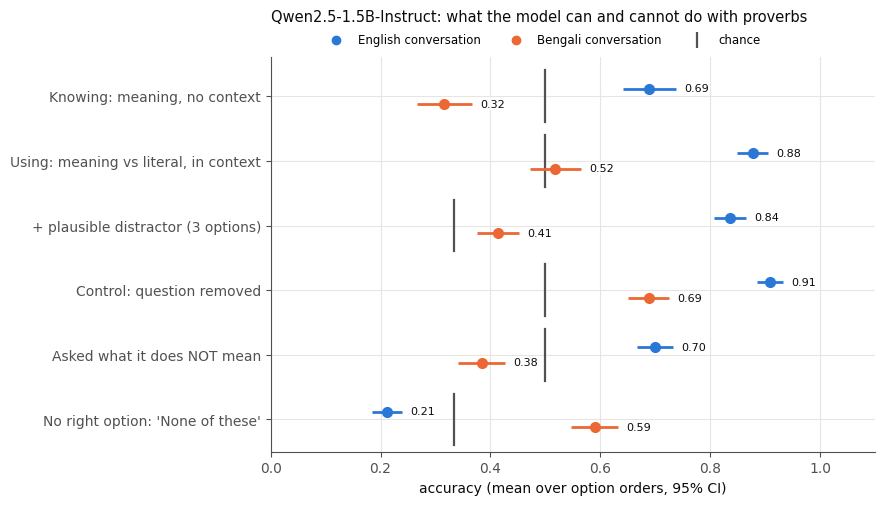

In [13]:
BATTERY = [("x4", "Knowing: meaning, no context"),
           ("x1", "Using: meaning vs literal, in context"),
           ("x5", "+ plausible distractor (3 options)"),
           ("x7", "Control: question removed"),
           ("x2", "Asked what it does NOT mean"),
           ("x3", "No right option: 'None of these'")]

def battery_plot(ov, title, name):
    rows = [(e, n) for e, n in BATTERY if any(get_ov(ov, f"{e}_{l}") is not None for l in LANGS)]
    if not rows:
        print("battery: nothing to plot"); return
    fig, ax = plt.subplots(figsize=(7.8, 0.62 * len(rows) + 1.4))
    for i, (e, _) in enumerate(rows):
        for j, l in enumerate(LANGS):
            r = get_ov(ov, f"{e}_{l}")
            if r is None:
                continue
            y = i + (j - (len(LANGS) - 1) / 2) * 0.24
            ax.errorbar(r[MAIN], y, xerr=[[r[MAIN] - r["ci_lo"]], [r["ci_hi"] - r[MAIN]]], fmt="o", ms=7, lw=2,
                        color=LANG_COLOR[l], capsize=0, zorder=3, label=LANG_NAME[l] if i == 0 else None)
            ax.text(min(r["ci_hi"], 1) + 0.015, y, f"{r[MAIN]:.2f}", va="center", fontsize=8, color=INK, bbox=LABEL_BOX)
        ch = ov.loc[ov["label"].str.startswith(e + "_"), "chance"].iloc[0]
        ax.plot([ch, ch], [i - 0.4, i + 0.4], color=MUTED, lw=1.6, zorder=2)
    ax.set_yticks(range(len(rows)), [n for _, n in rows])
    ax.set_ylim(len(rows) - 0.5, -0.6)
    ax.set_xlim(0, 1.1)
    ax.set_xlabel(f"accuracy ({METRIC_NAME[MAIN]}, 95% CI)")
    handles = [Line2D([], [], marker="o", ls="", color=LANG_COLOR[l], label=LANG_NAME[l]) for l in LANGS]
    handles.append(Line2D([], [], marker="|", ls="", ms=12, mew=1.6, color=MUTED, label="chance"))
    ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=3, fontsize=8.5)
    ax.set_title(title, pad=26)
    save(fig, name)

battery_plot(OV, f"{RUN_NAME}: what the model can and cannot do with proverbs", "A1_battery")

### A2 · Does the option order matter?
- **Left:** share of items where the model picks the same option in every order. Low values mean the answer depends on where an option sits.
- **Right:** accuracy in the ordinary order (hollow), averaged over orders (filled) and right-in-every-order (×). A large spread is position bias.

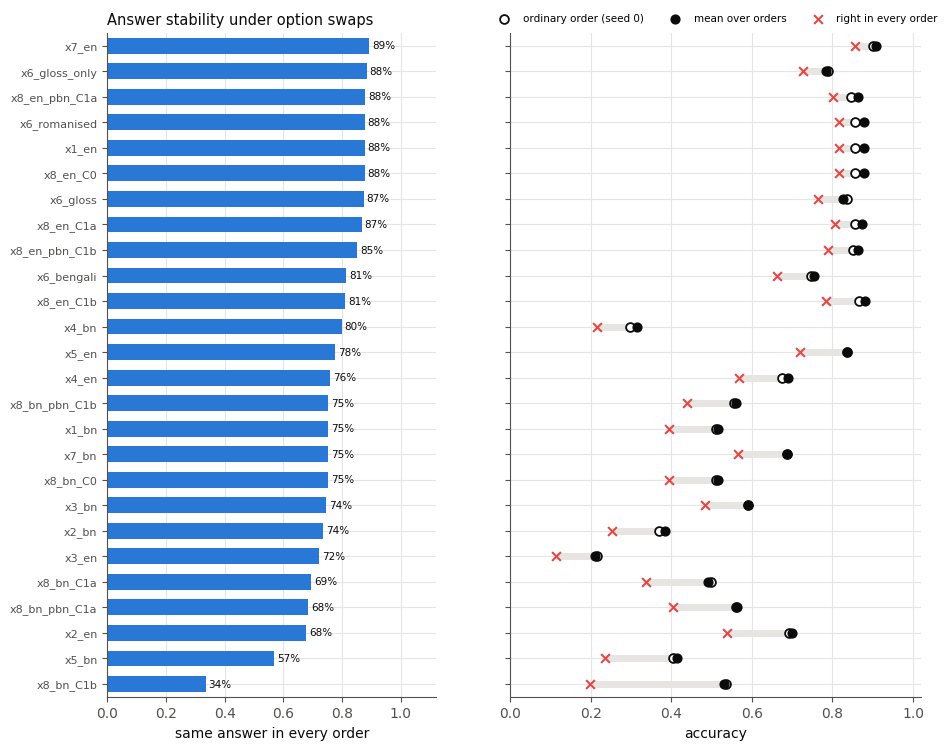

gold,acc_when_gold_a,acc_when_gold_b,acc_when_gold_c
label,,,
x1_bn,0.557,0.477,NaN
x1_en,0.823,0.933,NaN
x2_bn,0.405,0.363,NaN
x2_en,0.633,0.765,NaN
x3_bn,NaN,NaN,0.590
x3_en,NaN,NaN,0.212
x4_bn,0.353,0.278,NaN
x4_en,0.662,0.717,NaN
x5_bn,0.460,0.398,0.382


In [14]:
def order_plot(ov, name):
    t = ov[ov["orders"] > 1].copy()
    if t.empty:
        print("only one option order was scored (ORDERS='seed0'): nothing to compare"); return
    t = t.sort_values("consistent", ascending=False).reset_index(drop=True)
    y = np.arange(len(t))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 0.27 * len(t) + 1.6), sharey=True,
                                 gridspec_kw={"width_ratios": [1, 1.25]})
    a1.barh(y, t["consistent"], height=0.62, color="#2a78d6")
    for yi, v in zip(y, t["consistent"]):
        a1.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=7.5, color=INK)
    a1.set_xlim(0, 1.12); a1.set_xlabel("same answer in every order")
    a1.set_yticks(y, t["label"], fontsize=8); a1.set_ylim(len(t) - 0.5, -0.5)
    a1.set_title("Answer stability under option swaps")
    a2.hlines(y, t[["acc_strict", "acc_seed0", "acc"]].min(axis=1), t[["acc_strict", "acc_seed0", "acc"]].max(axis=1),
              color=GRID, lw=5, zorder=1)
    a2.scatter(t["acc_seed0"], y, s=40, facecolor="white", edgecolor=INK, lw=1.3, zorder=3, label="ordinary order (seed 0)")
    a2.scatter(t["acc"], y, s=40, color=INK, zorder=4, label="mean over orders")
    a2.scatter(t["acc_strict"], y, s=40, marker="x", color=LOSS, lw=1.5, zorder=4, label="right in every order")
    a2.set_xlim(0, 1.02); a2.set_xlabel("accuracy")
    a2.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=7.5)
    save(fig, name)

order_plot(OV, "A2_order_robustness")
pos = R.groupby(["label", "gold"])["correct"].mean().unstack().add_prefix("acc_when_gold_")
display(pos.round(3))

## B. Knowing vs using
- **B1:** accuracy without context (x4, *knowing*) vs in a conversation (x1, *using*), per language. The gap between languages shrinks if the conversation makes up for missing knowledge.
- **B2:** each proverb is a dot, P(right) without vs with context.
- **B3:** counts of items in the four know/use groups.

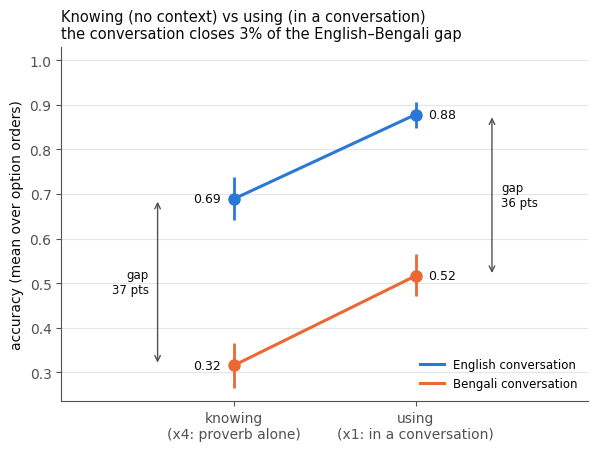

In [15]:
def know_use_slope(ov, name):
    if not all(get_ov(ov, f"{e}_{l}") is not None for e in ("x1", "x4") for l in LANGS):
        print("B1 needs x1 and x4 in both languages"); return {}
    fig, ax = plt.subplots(figsize=(6.8, 4.6))
    vals = {}
    for l in LANGS:
        k, u = get_ov(ov, f"x4_{l}"), get_ov(ov, f"x1_{l}")
        vals[l] = (k[MAIN], u[MAIN])
        ax.plot([0, 1], [k[MAIN], u[MAIN]], color=LANG_COLOR[l], lw=2.2, zorder=2, label=LANG_NAME[l])
        for x, r in ((0, k), (1, u)):
            ax.errorbar(x, r[MAIN], yerr=[[r[MAIN] - r["ci_lo"]], [r["ci_hi"] - r[MAIN]]], fmt="o", ms=8,
                        color=LANG_COLOR[l], capsize=0, lw=2, zorder=3)
            ax.text(x + (0.07 if x else -0.07), r[MAIN], f"{r[MAIN]:.2f}", va="center", ha="left" if x else "right",
                    fontsize=9, color=INK)
    title = "Knowing (no context) vs using (in a conversation)"
    if len(LANGS) == 2:
        gk, gu = vals["en"][0] - vals["bn"][0], vals["en"][1] - vals["bn"][1]
        for x, g in ((0, gk), (1, gu)):
            lo, hi = sorted([vals["en"][x], vals["bn"][x]])
            xx = -0.42 if x == 0 else 1.42
            ax.annotate("", xy=(xx, lo), xytext=(xx, hi), arrowprops=dict(arrowstyle="<->", color=MUTED, lw=1))
            ax.text(xx + (-0.05 if x == 0 else 0.05), (lo + hi) / 2, f"gap\n{g * 100:.0f} pts", fontsize=8.5,
                    color=INK, va="center", ha="right" if x == 0 else "left")
        if gk > 0 and gu <= gk:
            title += f"\nthe conversation closes {1 - gu / gk:.0%} of the English–Bengali gap"
        elif gk > 0:
            title += f"\nthe English–Bengali gap grows from {gk * 100:.0f} to {gu * 100:.0f} pts in a conversation"
    ax.set_title(title)
    ax.set_xticks([0, 1], ["knowing\n(x4: proverb alone)", "using\n(x1: in a conversation)"])
    ax.set_xlim(-0.95, 1.95)
    lo_y = min(min(v) for v in vals.values())
    ax.set_ylim(max(0, min(0.45, lo_y - 0.08)), 1.03)
    ax.set_ylabel(f"accuracy ({METRIC_NAME[MAIN]})")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower right", fontsize=8.5)
    save(fig, name)
    return vals

KU = know_use_slope(OV, "B1_knowing_vs_using")

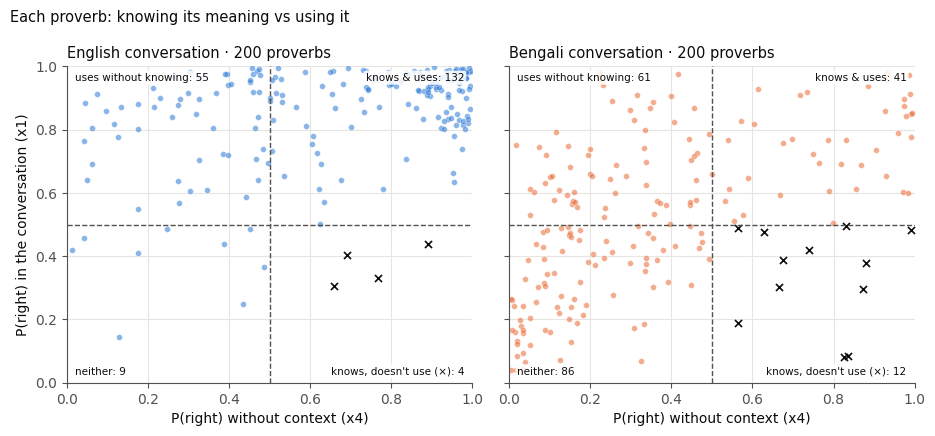

,lang,knows_meaning (x4),items,uses (x1 right),acc_in_context,ci_lo,ci_hi
0,en,False,114,99,0.781,0.700,0.856
1,en,True,486,465,0.901,0.873,0.927
2,bn,False,350,183,0.407,0.355,0.462
3,bn,True,250,201,0.670,0.612,0.727


In [16]:
def know_use_scatter(name):
    langs = [l for l in LANGS if has(f"x4_{l}", f"x1_{l}")]
    if not langs:
        return
    fig, axes = plt.subplots(1, len(langs), figsize=(4.7 * len(langs), 4.4), sharey=True, squeeze=False)
    for ax, l in zip(axes[0], langs):
        k = item_level(sub(f"x4_{l}"), ()).groupby("proverb_id")["p_gold"].mean()
        u = item_level(sub(f"x1_{l}"), ()).groupby("proverb_id")["p_gold"].mean()
        m = pd.concat([k.rename("know"), u.rename("use")], axis=1).dropna()
        trap = (m["know"] > 0.5) & (m["use"] < 0.5)
        ax.scatter(m.loc[~trap, "know"], m.loc[~trap, "use"], s=18, alpha=0.55, color=LANG_COLOR[l],
                   edgecolors="white", linewidths=0.4)
        ax.scatter(m.loc[trap, "know"], m.loc[trap, "use"], s=26, color=INK, marker="x", lw=1.2)
        ax.axhline(0.5, color=MUTED, lw=1, ls="--"); ax.axvline(0.5, color=MUTED, lw=1, ls="--")
        q = lambda a, b: int((((m["know"] > 0.5) == a) & ((m["use"] > 0.5) == b)).sum())
        for (x, y, ha, va, txt) in [(0.98, 0.98, "right", "top", f"knows & uses\n{q(True, True)}"),
                                    (0.02, 0.98, "left", "top", f"uses without knowing\n{q(False, True)}"),
                                    (0.02, 0.02, "left", "bottom", f"neither\n{q(False, False)}"),
                                    (0.98, 0.02, "right", "bottom", f"knows, doesn't use (×)\n{q(True, False)}")]:
            ax.text(x, y, txt.replace("\n", ": "), transform=ax.transAxes, ha=ha, va=va, fontsize=7.5, color=INK,
                    zorder=5, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xlabel("P(right) without context (x4)")
        ax.set_title(f"{LANG_NAME[l]} · {len(m)} proverbs")
    axes[0, 0].set_ylabel("P(right) in the conversation (x1)")
    fig.suptitle("Each proverb: knowing its meaning vs using it", x=0.01, ha="left", fontsize=10.5, color=INK)
    fig.tight_layout()
    save(fig, name)

know_use_scatter("B2_knowing_vs_using_per_proverb")

rows = []
for l in LANGS:
    if not has(f"x4_{l}", f"x1_{l}"):
        continue
    m = item_level(sub(f"x1_{l}"), ()).merge(item_level(sub(f"x4_{l}"), ())[["item_id", "correct"]],
                                            on="item_id", suffixes=("", "_know"))
    m["knows"], m["uses"] = m["correct_know"] >= 0.5, m["correct"] >= 0.5
    for kn, g in m.groupby("knows"):
        lo, hi = ci(g["correct"], g["proverb_id"])
        rows.append({"lang": l, "knows_meaning (x4)": kn, "items": len(g), "uses (x1 right)": int(g["uses"].sum()),
                     "acc_in_context": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi})
KNOW_TAB = pd.DataFrame(rows)
KNOW_TAB.to_csv(TAB / "B3_knowing_vs_using.csv", index=False)
display(KNOW_TAB.round(3))

## C. Does the model follow the question?
The same two options (figurative meaning vs literal reading) under three questions. A model that reads the question picks the meaning when asked *what it means* and avoids it when asked *what it does NOT mean*. If the three bars look alike, the question is being ignored.

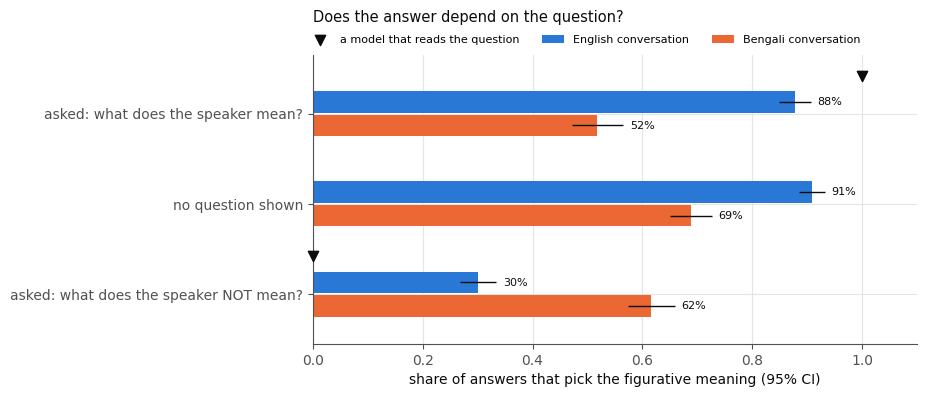

,question,lang,picks_meaning,ci_lo,ci_hi
0,x1,en,0.878,0.848,0.906
1,x1,bn,0.517,0.472,0.565
2,x7,en,0.909,0.885,0.932
3,x7,bn,0.688,0.650,0.726
4,x2,en,0.301,0.268,0.334
5,x2,bn,0.616,0.574,0.658


,lang,acc_meaning_q,acc_NOT_q,sum (~1 = ignores NOT),same_option_both,both_right,items
0,en,0.878,0.699,1.578,0.445,0.822,600
1,bn,0.517,0.384,0.901,0.888,0.175,600


In [17]:
def question_plot(name):
    conds = [("x1", "asked: what does the speaker mean?"), ("x7", "no question shown"),
             ("x2", "asked: what does the speaker NOT mean?")]
    conds = [(e, t) for e, t in conds if any(has(f"{e}_{l}") for l in LANGS)]
    if not conds:
        return None
    fig, ax = plt.subplots(figsize=(7.8, 0.75 * len(conds) + 1.5))
    rows = []
    for i, (e, t) in enumerate(conds):
        for j, l in enumerate(LANGS):
            if not has(f"{e}_{l}"):
                continue
            it = item_level(sub(f"{e}_{l}"), ())
            v = it["pick_correct"].mean()
            lo, hi = ci(it["pick_correct"], it["proverb_id"])
            y = i + (j - (len(LANGS) - 1) / 2) * 0.26
            ax.barh(y, v, height=0.24, color=LANG_COLOR[l], label=LANG_NAME[l] if i == 0 else None)
            ax.errorbar(v, y, xerr=[[v - lo], [hi - v]], fmt="none", ecolor=INK, lw=1, capsize=0)
            ax.text(hi + 0.012, y, f"{v:.0%}", va="center", fontsize=8, color=INK)
            rows.append({"question": e, "lang": l, "picks_meaning": v, "ci_lo": lo, "ci_hi": hi})
        ideal = {"x1": 1.0, "x2": 0.0}.get(e)
        if ideal is not None:
            ax.scatter(ideal, i - 0.42, marker="v", s=55, color=INK, zorder=4,
                       label="a model that reads the question" if e == "x1" else None, clip_on=False)
    ax.set_yticks(range(len(conds)), [t for _, t in conds])
    ax.set_ylim(len(conds) - 0.45, -0.65); ax.set_xlim(0, 1.1)
    ax.set_xlabel("share of answers that pick the figurative meaning (95% CI)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=3, fontsize=8)
    ax.set_title("Does the answer depend on the question?", pad=24)
    save(fig, name)
    return pd.DataFrame(rows)

Q_TAB = question_plot("C1_question_following")
if Q_TAB is not None:
    display(Q_TAB.round(3))

neg = []
for l in LANGS:
    if not has(f"x1_{l}", f"x2_{l}"):
        continue
    m = item_level(sub(f"x1_{l}"), ()).merge(item_level(sub(f"x2_{l}"), ()), on="item_id", suffixes=("_pos", "_neg"))
    same = (m["pick_correct_pos"] >= 0.5) == (m["pick_correct_neg"] >= 0.5)
    neg.append({"lang": l, "acc_meaning_q": m["correct_pos"].mean(), "acc_NOT_q": m["correct_neg"].mean(),
                "sum (~1 = ignores NOT)": m["correct_pos"].mean() + m["correct_neg"].mean(),
                "same_option_both": same.mean(),
                "both_right": ((m["correct_pos"] >= 0.5) & (m["correct_neg"] >= 0.5)).mean(), "items": len(m)})
NEG_TAB = pd.DataFrame(neg)
NEG_TAB.to_csv(TAB / "C2_negation.csv", index=False)
display(NEG_TAB.round(3))

## D. What does the model pick?
- **D1:** answer shares by option for the 3-option tasks: x5 (correct, literal, plausible) and x3 (no correct option: literal, plausible, "None of these").
- **D2:** for x5, where the probability goes. Each item is a point inside the triangle (probabilities averaged over orders); corners are confident answers.
- **D3:** how the proverb is shown in English conversations (x6), compared with romanised.

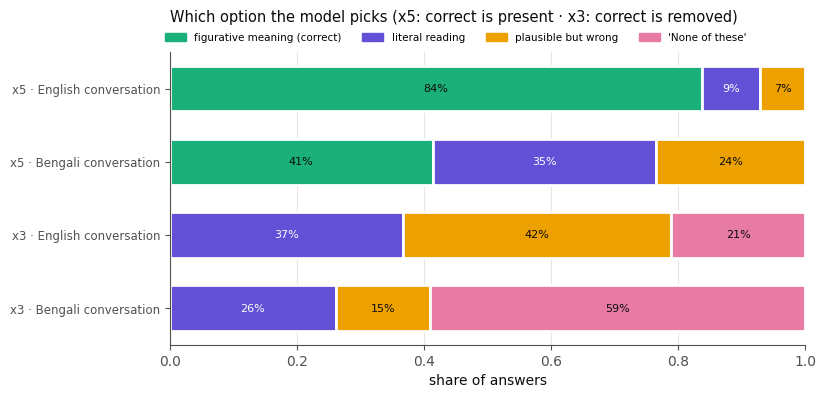

,label,correct,literal,plausible,none,literal_share_of_errors
0,x5_en,0.837,0.092,0.071,0.000,0.565
1,x5_bn,0.413,0.352,0.235,0.000,0.599
2,x3_en,0.000,0.367,0.422,0.212,0.465
3,x3_bn,0.000,0.262,0.148,0.590,0.638


In [18]:
def picks_plot(name):
    bars = [(f"{e}_{l}", f"{e} · {LANG_NAME[l]}") for e in ("x5", "x3") for l in LANGS if has(f"{e}_{l}")]
    if not bars:
        return None
    fig, ax = plt.subplots(figsize=(8.2, 0.55 * len(bars) + 1.6))
    tab = []
    for i, (lab, txt) in enumerate(bars):
        d = sub(lab)
        left = 0
        shares = {k: d[f"pick_{k}"].mean() for k in KEYS}
        tab.append({"label": lab, **shares})
        for k in KEYS:
            w = shares[k]
            if w <= 0:
                continue
            ax.barh(i, w, left=left, height=0.62, color=KEY_COLOR[k], edgecolor="white", linewidth=2)
            if w >= 0.07:
                ax.text(left + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=8, color=text_on(KEY_COLOR[k]))
            left += w
    ax.set_yticks(range(len(bars)), [t for _, t in bars], fontsize=8.5)
    ax.set_ylim(len(bars) - 0.5, -0.5); ax.set_xlim(0, 1)
    ax.set_xlabel("share of answers")
    handles = [Patch(color=KEY_COLOR[k], label=KEY_NAME[k]) for k in KEYS]
    ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=4, fontsize=7.5)
    ax.set_title("Which option the model picks (x5: correct is present · x3: correct is removed)", pad=22)
    ax.grid(axis="y", visible=False)
    save(fig, name)
    return pd.DataFrame(tab)

PICK_TAB = picks_plot("D1_picks")
if PICK_TAB is not None:
    PICK_TAB["literal_share_of_errors"] = PICK_TAB["literal"] / (PICK_TAB["literal"] + PICK_TAB["plausible"])
    display(PICK_TAB.round(3))

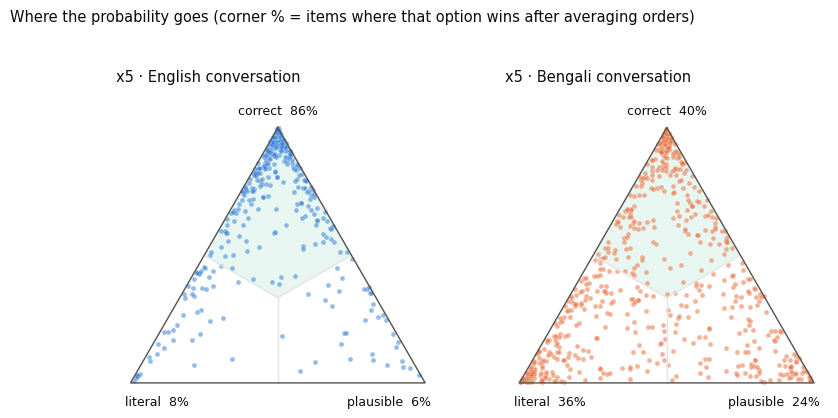

In [19]:
def triangle_plot(name):
    langs = [l for l in LANGS if has(f"x5_{l}")]
    if not langs:
        return
    TOP, BL, BR = np.array([0.5, np.sqrt(3) / 2]), np.array([0.0, 0.0]), np.array([1.0, 0.0])
    fig, axes = plt.subplots(1, len(langs), figsize=(4.6 * len(langs), 4.6), squeeze=False)
    for ax, l in zip(axes[0], langs):
        d = item_level(sub(f"x5_{l}"), ())
        P = d[["p_correct", "p_literal", "p_plausible"]].to_numpy()
        P = P / P.sum(axis=1, keepdims=True)
        xy = np.outer(P[:, 0], TOP) + np.outer(P[:, 1], BL) + np.outer(P[:, 2], BR)
        ctr = (TOP + BL + BR) / 3
        ax.fill([TOP[0], (TOP + BL)[0] / 2, ctr[0], (TOP + BR)[0] / 2],
                [TOP[1], (TOP + BL)[1] / 2, ctr[1], (TOP + BR)[1] / 2], color=KEY_COLOR["correct"], alpha=0.1, lw=0)
        for mid in [(TOP + BL) / 2, (TOP + BR) / 2, (BL + BR) / 2]:
            ax.plot([ctr[0], mid[0]], [ctr[1], mid[1]], color=GRID, lw=1)
        ax.plot(*np.array([TOP, BL, BR, TOP]).T, color=MUTED, lw=1)
        ax.scatter(xy[:, 0], xy[:, 1], s=13, alpha=0.5, color=LANG_COLOR[l], edgecolors="white", linewidths=0.3)
        win = d["pred_key_db"].value_counts(normalize=True)
        for k, pt, dx, dy, ha in [("correct", TOP, 0, 0.045, "center"), ("literal", BL, -0.02, -0.075, "left"),
                                  ("plausible", BR, 0.02, -0.075, "right")]:
            ax.text(pt[0] + dx, pt[1] + dy, f"{k}  {win.get(k, 0):.0%}", ha=ha, fontsize=9, color=INK)
        ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(f"x5 · {LANG_NAME[l]}", pad=24)
    fig.suptitle("Where the probability goes (corner % = items where that option wins after averaging orders)",
                 x=0.01, ha="left", fontsize=10.5, color=INK, y=1.03)
    save(fig, name)

triangle_plot("D2_x5_triangle")

,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,x6_gloss,0.878,0.827,-0.052,-0.085,-0.021,91,49,600
1,x6_gloss_only,0.878,0.785,-0.093,-0.130,-0.056,120,45,600
2,x6_bengali,0.878,0.755,-0.123,-0.152,-0.094,132,17,600


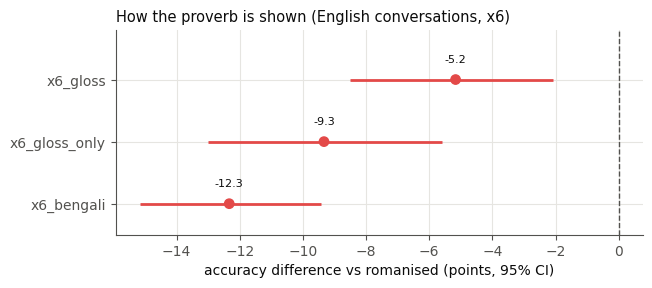

In [20]:
def forest(tab, title, name, ref_name):
    if tab.empty:
        return
    fig, ax = plt.subplots(figsize=(6.8, 0.42 * len(tab) + 1.4))
    y = np.arange(len(tab))
    cols = [GAIN if lo > 0 else LOSS if hi < 0 else MUTED for lo, hi in zip(tab["ci_lo"], tab["ci_hi"])]
    ax.errorbar(tab["diff"] * 100, y, xerr=[(tab["diff"] - tab["ci_lo"]) * 100, (tab["ci_hi"] - tab["diff"]) * 100],
                fmt="none", ecolor=cols, lw=2, capsize=0)
    ax.scatter(tab["diff"] * 100, y, color=cols, s=45, zorder=3)
    for yi, d in zip(y, tab["diff"]):
        ax.text(d * 100, yi - 0.28, f"{d * 100:+.1f}", ha="center", fontsize=8, color=INK)
    ax.axvline(0, color=MUTED, ls="--", lw=1)
    ax.set_yticks(y, tab["b"]); ax.set_ylim(len(tab) - 0.5, -0.8)
    ax.set_xlabel(f"accuracy difference vs {ref_name} (points, 95% CI)")
    ax.set_title(title)
    save(fig, name)

if has("x6_romanised"):
    X6_TAB = pd.DataFrame([{"b": l, **paired(sub("x6_romanised"), g)} for l, g in R[R["exp"] == "x6"].groupby("label")
                           if l != "x6_romanised"])
    if not X6_TAB.empty:
        X6_TAB = X6_TAB.sort_values("diff", ascending=False).reset_index(drop=True)
        X6_TAB.to_csv(TAB / "D3_renders.csv", index=False)
        display(X6_TAB.round(3))
        forest(X6_TAB, "How the proverb is shown (English conversations, x6)", "D3_renders", "romanised")

## E. Shortcut check: word overlap
A no-understanding baseline picks the option that shares the most words with the conversation, ignoring the proverb's own line; ties count half.
- **Left:** how far that shortcut gets on each option pairing.
- **Right:** the model's x1 accuracy when the shortcut points to the right answer vs when it points to the wrong one. If the model leaned on overlap, it would collapse where the cue is wrong.

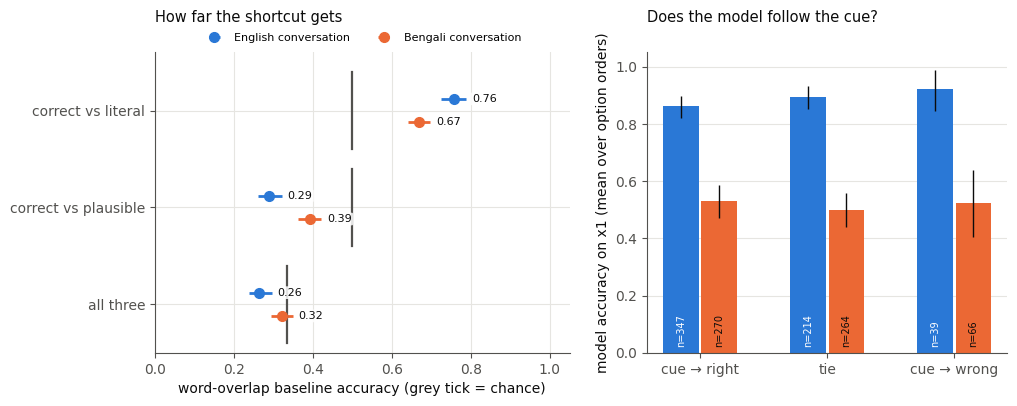

,correct vs literal,correct vs plausible,all three
lang,,,
bn,0.670,0.392,0.322
en,0.757,0.289,0.264


,lang,cue,items,model_acc,ci_lo,ci_hi
0,en,cue → right answer,347,0.863,0.822,0.899
1,en,tie,214,0.895,0.854,0.934
2,en,cue → wrong answer,39,0.923,0.846,0.987
3,bn,cue → right answer,270,0.531,0.470,0.587
4,bn,tie,264,0.500,0.440,0.559
5,bn,cue → wrong answer,66,0.523,0.404,0.641


In [21]:
def _words(text, lang):
    stop = BN_STOPWORDS if lang == "bn" else EN_STOP
    return {t for t in re.findall(r"\w+", str(text).lower()) if t not in stop and len(t) > 1}

def _context_words(item, lang):
    b = item[lang]
    turns = b["turns"]
    idx = [i for i, t in enumerate(turns) if t["speaker"] == b["proverb_speaker"]]
    last = idx[-1] if idx else len(turns) - 1
    return _words(" ".join(t["text"] for i, t in enumerate(turns) if i != last), lang)

def _overlap(item, lang, keys):
    ctx, o = _context_words(item, lang), item[lang]["options"]
    ov = {k: len(ctx & _words(o[k], lang)) for k in keys}
    win = [k for k, v in ov.items() if v == max(ov.values())]
    return 1 / len(win) if "correct" in win else 0.0

items_run = [ITEM_BY_ID[i] for i in R["item_id"].unique() if i in ITEM_BY_ID]
OVL = pd.DataFrame([{"item_id": it["item_id"], "proverb_id": it["proverb"]["proverb_id"], "lang": l,
                     "correct vs literal": _overlap(it, l, ("correct", "literal")),
                     "correct vs plausible": _overlap(it, l, ("correct", "plausible")),
                     "all three": _overlap(it, l, ("correct", "literal", "plausible"))}
                    for it in items_run for l in LANGS])
PAIRINGS = [("correct vs literal", 0.5), ("correct vs plausible", 0.5), ("all three", 1 / 3)]

def shortcut_plot(name):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
    for i, (p, ch) in enumerate(PAIRINGS):
        for j, l in enumerate(LANGS):
            g = OVL[OVL["lang"] == l]
            v = g[p].mean(); lo, hi = ci(g[p], g["proverb_id"])
            y = i + (j - 0.5) * 0.24
            a1.errorbar(v, y, xerr=[[v - lo], [hi - v]], fmt="o", ms=7, color=LANG_COLOR[l], lw=2,
                        label=LANG_NAME[l] if i == 0 else None)
            a1.text(hi + 0.015, y, f"{v:.2f}", va="center", fontsize=8, color=INK, bbox=LABEL_BOX)
        a1.plot([ch, ch], [i - 0.4, i + 0.4], color=MUTED, lw=1.6)
    a1.set_yticks(range(len(PAIRINGS)), [p for p, _ in PAIRINGS]); a1.set_ylim(len(PAIRINGS) - 0.5, -0.6)
    a1.set_xlim(0, 1.05); a1.set_xlabel("word-overlap baseline accuracy (grey tick = chance)")
    a1.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8)
    a1.set_title("How far the shortcut gets", pad=22)
    rows = []
    for j, l in enumerate(LANGS):
        if not has(f"x1_{l}"):
            continue
        m = item_level(sub(f"x1_{l}"), ()).merge(OVL[OVL["lang"] == l][["item_id", "correct vs literal"]], on="item_id")
        m["cue"] = m["correct vs literal"].map({1.0: "cue → right answer", 0.5: "tie", 0.0: "cue → wrong answer"})
        for i, cue in enumerate(["cue → right answer", "tie", "cue → wrong answer"]):
            g = m[m["cue"] == cue]
            if g.empty:
                continue
            v = g[METRIC_COL[MAIN]].mean(); lo, hi = ci(g[METRIC_COL[MAIN]], g["proverb_id"])
            x = i + (j - 0.5) * 0.3
            a2.bar(x, v, width=0.28, color=LANG_COLOR[l])
            a2.errorbar(x, v, yerr=[[v - lo], [hi - v]], fmt="none", ecolor=INK, lw=1)
            a2.text(x, 0.02, f"n={len(g)}", ha="center", fontsize=7, color=text_on(LANG_COLOR[l]), rotation=90, va="bottom")
            rows.append({"lang": l, "cue": cue, "items": len(g), "model_acc": v, "ci_lo": lo, "ci_hi": hi})
    a2.set_xticks(range(3), ["cue → right", "tie", "cue → wrong"]); a2.set_ylim(0, 1.05)
    a2.set_ylabel(f"model accuracy on x1 ({METRIC_NAME[MAIN]})")
    a2.set_title("Does the model follow the cue?", pad=22)
    a2.grid(axis="x", visible=False)
    save(fig, name)
    return pd.DataFrame(rows)

CUE_TAB = shortcut_plot("E1_overlap_shortcut")
display(OVL.groupby("lang")[[p for p, _ in PAIRINGS]].mean().round(3))
display(CUE_TAB.round(3))

## F. System prompts (x8)
x8 is the x1 task with a system prompt: C0 has none; C1a is a short persona and C1b a rich one, each written in English or in Bengali. "any prompt" is the share of items that at least one prompt gets right. It is an optimistic ceiling, because with 2 options some items come out right under one prompt by luck.

In [22]:
X8 = R[R["exp"] == "x8"].copy()
COND_ORDER = ["C0"] + [c for c in X8_CONDITIONS if c in set(X8["condition"])]
RUN_NAMES = {(pl, cv): f"{pl} prompt · {cv} conv" for pl in ("en", "bn") for cv in LANGS}

def x8_rows(conv, pl, cond):
    if cond == "C0":
        return X8[(X8["conv_lang"] == conv) & (X8["condition"] == "C0")]
    return X8[(X8["conv_lang"] == conv) & (X8["prompt_lang"] == pl) & (X8["condition"] == cond)]

def prompt_table():
    rows = []
    for conv in LANGS:
        base = x8_rows(conv, None, "C0")
        if base.empty:
            continue
        for pl in ("en", "bn"):
            conds = [c for c in COND_ORDER if not x8_rows(conv, pl, c).empty]
            if len(conds) < 2:
                continue
            right = pd.concat({c: item_level(x8_rows(conv, pl, c), ()).set_index(["item_id", "proverb_id"])[METRIC_COL[MAIN]] >= 0.5
                               for c in conds}, axis=1)
            for c in conds:
                it = item_level(x8_rows(conv, pl, c), ())
                lo, hi = ci(it[METRIC_COL[MAIN]], it["proverb_id"])
                r = {"conv": conv, "prompt_lang": pl, "cond": c, "acc": it[METRIC_COL[MAIN]].mean(), "ci_lo": lo, "ci_hi": hi,
                     "consistent": it["consistent"].mean(), "n": len(it)}
                if c != "C0":
                    p = paired(base, x8_rows(conv, pl, c))
                    r.update({"diff_vs_C0": p["diff"], "diff_lo": p["ci_lo"], "diff_hi": p["ci_hi"],
                              "fixed_vs_C0": int((right[c] & ~right["C0"]).sum()),
                              "broken_vs_C0": int((~right[c] & right["C0"]).sum())})
                r["only_this_prompt"] = int((right[c] & ~right.drop(columns=c).any(axis=1)).sum())
                rows.append(r)
            anyr = right.any(axis=1).astype(float)
            lo, hi = ci(anyr, right.index.get_level_values("proverb_id"))
            rows.append({"conv": conv, "prompt_lang": pl, "cond": "any prompt", "acc": anyr.mean(), "ci_lo": lo,
                         "ci_hi": hi, "n": len(anyr)})
    t = pd.DataFrame(rows)
    if not t.empty and "fixed_vs_C0" in t:
        t["net_vs_C0"] = t["fixed_vs_C0"] - t["broken_vs_C0"]
    return t

PT = prompt_table() if not X8.empty else pd.DataFrame()
if not PT.empty:
    PT.to_csv(TAB / "F0_system_prompts.csv", index=False)
    display(PT.round(3))

,conv,prompt_lang,cond,acc,ci_lo,ci_hi,consistent,n,only_this_prompt,diff_vs_C0,diff_lo,diff_hi,fixed_vs_C0,broken_vs_C0,net_vs_C0
0,en,en,C0,0.878,0.848,0.906,0.877,600,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,en,en,C1a,0.873,0.844,0.900,0.867,600,0.0,-0.005,-0.019,0.008,5.0,5.0,0.0
2,en,en,C1b,0.880,0.853,0.903,0.810,600,17.0,0.002,-0.016,0.018,22.0,1.0,21.0
3,en,en,any prompt,0.977,0.960,0.990,NaN,600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,en,bn,C0,0.878,0.848,0.906,0.877,600,10.0,NaN,NaN,NaN,NaN,NaN,NaN
5,en,bn,C1a,0.862,0.831,0.891,0.878,600,0.0,-0.016,-0.028,-0.003,5.0,15.0,-10.0
6,en,bn,C1b,0.862,0.834,0.890,0.852,600,6.0,-0.016,-0.031,-0.001,11.0,13.0,-2.0
7,en,bn,any prompt,0.958,0.938,0.975,NaN,600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,bn,en,C0,0.517,0.472,0.565,0.753,600,10.0,NaN,NaN,NaN,NaN,NaN,NaN
9,bn,en,C1a,0.490,0.448,0.532,0.693,600,0.0,-0.027,-0.046,-0.008,32.0,30.0,2.0


### F1 · Prompt ladder and F2 · persona effect map
- **F1:** accuracy for each prompt, one line per (prompt language, conversation language) pair. The hollow markers are the any-prompt ceiling.
- **F2:** each persona's effect relative to no system prompt, for every combination of prompt and conversation language (blue = helps, red = hurts).

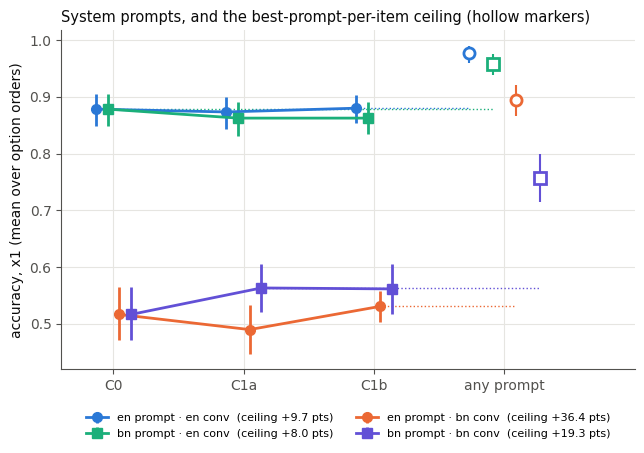

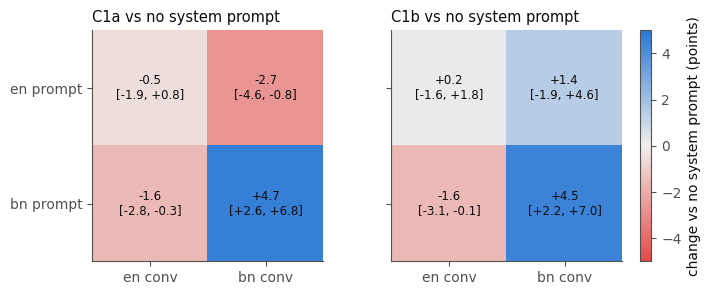

In [23]:
def prompt_ladder(name):
    if PT.empty:
        return
    xs = {c: i for i, c in enumerate(COND_ORDER + ["any prompt"])}
    runs = [(pl, cv) for cv in LANGS for pl in ("en", "bn")
            if not PT[(PT["conv"] == cv) & (PT["prompt_lang"] == pl)].empty]
    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    for j, (pl, cv) in enumerate(runs):
        col, mk = RUN_STYLE[(pl, cv)]
        t = PT[(PT["conv"] == cv) & (PT["prompt_lang"] == pl)].set_index("cond")
        real = [c for c in COND_ORDER if c in t.index]
        ceil, best = t.loc["any prompt"], t.loc[real, "acc"].max()
        off = (j - (len(runs) - 1) / 2) * 0.09
        ax.errorbar([xs[c] + off for c in real], t.loc[real, "acc"],
                    yerr=[t.loc[real, "acc"] - t.loc[real, "ci_lo"], t.loc[real, "ci_hi"] - t.loc[real, "acc"]],
                    color=col, lw=2, marker=mk, ms=7, capsize=0,
                    label=f"{RUN_NAMES[(pl, cv)]}  (ceiling +{(ceil['acc'] - best) * 100:.1f} pts)")
        xc = xs["any prompt"] + (j - (len(runs) - 1) / 2) * 0.18
        ax.errorbar(xc, ceil["acc"], yerr=[[ceil["acc"] - ceil["ci_lo"]], [ceil["ci_hi"] - ceil["acc"]]],
                    color=col, marker=mk, ms=8, mfc="white", mew=2, capsize=0, ls="none", elinewidth=1.5)
        ax.hlines(best, xs[t.loc[real, "acc"].idxmax()] + off, xc, colors=col, linestyles=":", lw=1)
    ax.set_xticks(list(xs.values()), list(xs.keys()))
    ax.set_xlim(-0.4, len(xs) - 0.4 + 0.1 * len(runs))
    ax.set_ylabel(f"accuracy, x1 ({METRIC_NAME[MAIN]})")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8)
    ax.set_title("System prompts, and the best-prompt-per-item ceiling (hollow markers)")
    save(fig, name)

def persona_map(name):
    if PT.empty or "diff_vs_C0" not in PT:
        return
    conds = [c for c in COND_ORDER if c != "C0"]
    fig, axes = plt.subplots(1, len(conds), figsize=(3.0 * len(conds) + 1.6, 3.0), squeeze=False, sharey=True)
    vmax = max(5.0, 100 * np.nanmax(np.abs(PT["diff_vs_C0"].to_numpy(dtype=float))))
    cmap = LinearSegmentedColormap.from_list("div", [LOSS, MID, GAIN])
    for ax, c in zip(axes[0], conds):
        M = np.full((2, len(LANGS)), np.nan)
        for i, pl in enumerate(("en", "bn")):
            for j, cv in enumerate(LANGS):
                r = PT[(PT["conv"] == cv) & (PT["prompt_lang"] == pl) & (PT["cond"] == c)]
                if not r.empty:
                    M[i, j] = 100 * r["diff_vs_C0"].iat[0]
                    cell = cmap(0.5 + M[i, j] / (2 * vmax))
                    ax.text(j, i, f"{M[i, j]:+.1f}\n[{r['diff_lo'].iat[0] * 100:+.1f}, {r['diff_hi'].iat[0] * 100:+.1f}]",
                            ha="center", va="center", fontsize=8.5, color=text_on(cell))
        im = ax.imshow(M, cmap=cmap, vmin=-vmax, vmax=vmax)
        ax.set_xticks(range(len(LANGS)), [f"{l} conv" for l in LANGS]); ax.set_yticks([0, 1], ["en prompt", "bn prompt"])
        ax.grid(False)
        ax.set_title(f"{c} vs no system prompt")
    cb = fig.colorbar(im, ax=axes[0].tolist(), fraction=0.04, pad=0.03)
    cb.set_label("change vs no system prompt (points)")
    save(fig, name)

prompt_ladder("F1_prompt_ladder")
persona_map("F2_persona_effect_map")

### F3 · Fixed vs broken, F4 · confidence migration, F5 · which prompts solve the same items
- **F3:** items each prompt turns from wrong to right (blue) and from right to wrong (red), compared with C0.
- **F4:** each item's margin (log P(right) minus log P(wrong)) without a system prompt vs with one, coloured by whether the prompt rescued or broke it. *Your plot 1, fixed.*
- **F5:** UpSet plot of the exact combinations of prompts that solve each item. *Your plot 2, fixed so it works with any set of conditions.*

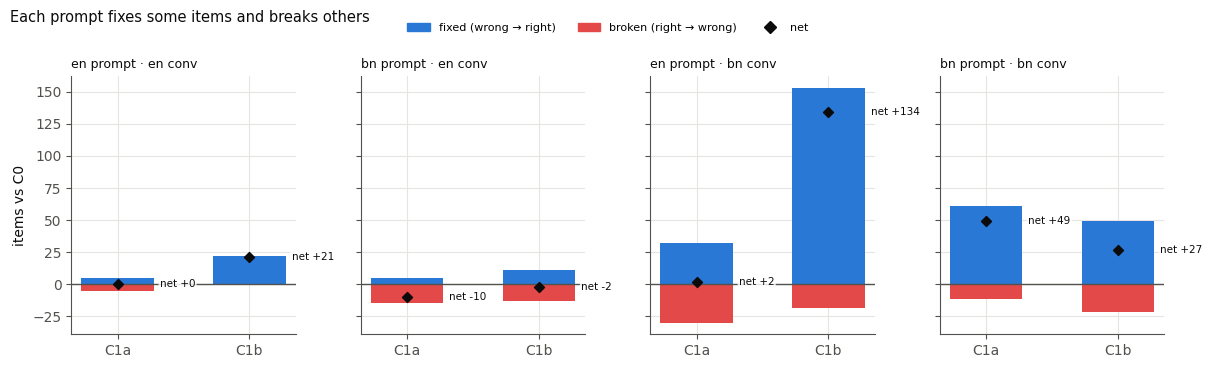

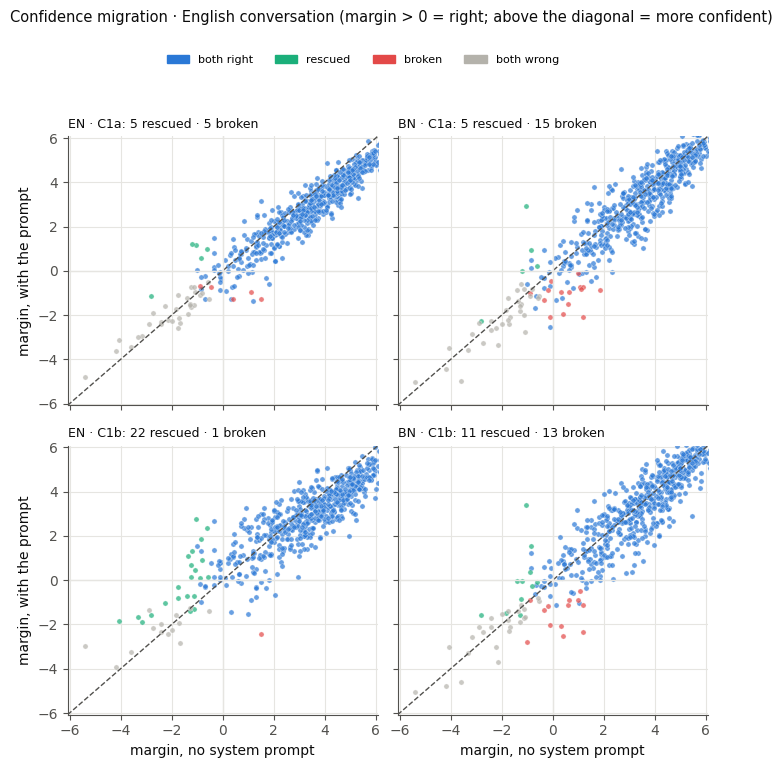

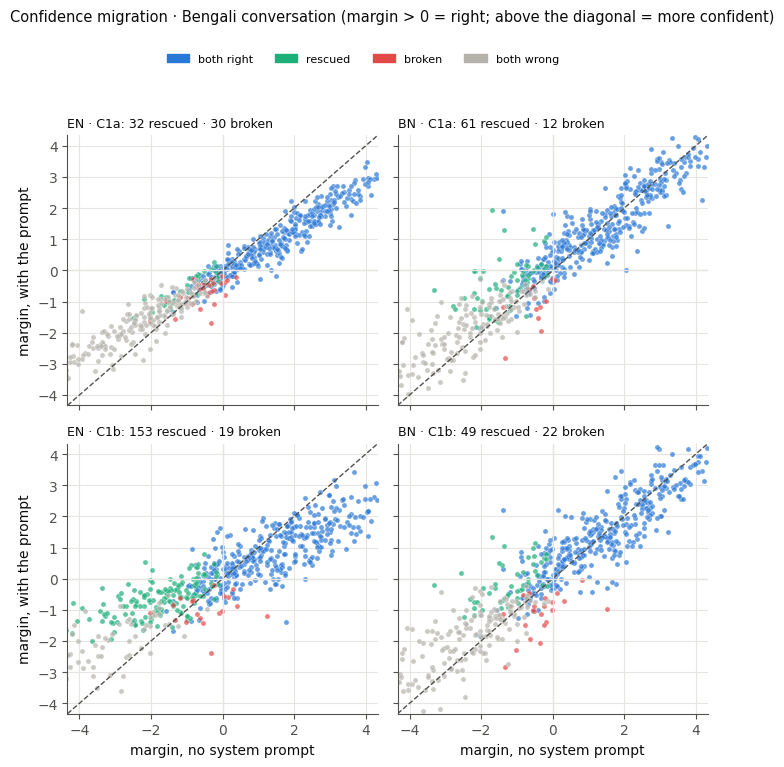

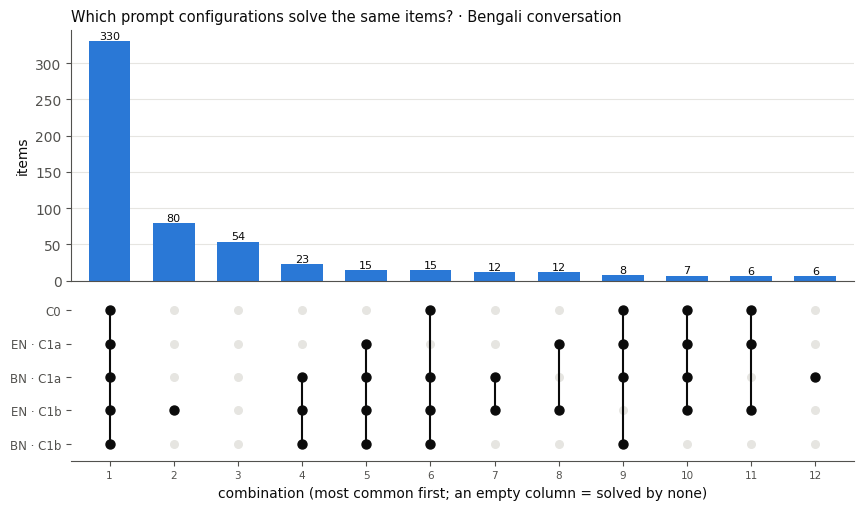

In [24]:
def fixed_broken(name):
    t = PT[PT["cond"].isin([c for c in COND_ORDER if c != "C0"])] if not PT.empty else PT
    if t.empty:
        return
    runs = [(pl, cv) for cv in LANGS for pl in ("en", "bn") if not t[(t["conv"] == cv) & (t["prompt_lang"] == pl)].empty]
    conds = [c for c in COND_ORDER if c != "C0"]
    fig, axes = plt.subplots(1, len(runs), figsize=(2.9 * len(runs) + 0.6, 3.3), sharey=True, squeeze=False)
    for ax, (pl, cv) in zip(axes[0], runs):
        tt = t[(t["conv"] == cv) & (t["prompt_lang"] == pl)].set_index("cond").reindex(conds)
        x = np.arange(len(conds))
        ax.bar(x, tt["fixed_vs_C0"], width=0.55, color=GAIN, label="fixed (wrong → right)")
        ax.bar(x, -tt["broken_vs_C0"], width=0.55, color=LOSS, label="broken (right → wrong)")
        ax.scatter(x, tt["net_vs_C0"], color=INK, marker="D", s=26, zorder=3, label="net")
        for xi, v, fx, br in zip(x, tt["net_vs_C0"], tt["fixed_vs_C0"], tt["broken_vs_C0"]):
            if pd.notna(v) and (fx or br):
                ax.text(xi + 0.32, v, f"net {v:+.0f}", va="center", fontsize=7.5, color=INK, bbox=LABEL_BOX)
        ax.axhline(0, color=MUTED, lw=1); ax.set_xticks(x, conds)
        ax.set_title(RUN_NAMES[(pl, cv)], fontsize=9)
    axes[0, 0].set_ylabel("items vs C0")
    fig.tight_layout()
    handles = [Patch(color=GAIN, label="fixed (wrong → right)"), Patch(color=LOSS, label="broken (right → wrong)"),
               Line2D([], [], marker="D", ls="", color=INK, label="net")]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8)
    fig.suptitle("Each prompt fixes some items and breaks others", x=0.01, ha="left", y=1.1, fontsize=10.5, color=INK)
    save(fig, name)

def prompt_matrix(conv, col):
    """items x prompt configurations (C0, EN · C1a, ...) for one conversation language."""
    out = {}
    for c in COND_ORDER:
        for pl in (("none",) if c == "C0" else ("en", "bn")):
            d = x8_rows(conv, pl, c)
            if not d.empty:
                out["C0" if c == "C0" else f"{pl.upper()} · {c}"] = item_level(d, ()).set_index(["item_id", "proverb_id"])[col]
    return pd.DataFrame(out)

def migration_plot(conv, name):
    M, RT = prompt_matrix(conv, "margin"), prompt_matrix(conv, METRIC_COL[MAIN]) >= 0.5
    others = [c for c in M.columns if c != "C0"]
    if "C0" not in M or not others:
        return
    ncol = 2 if len(others) in (2, 4) else min(3, len(others))
    nrow = int(np.ceil(len(others) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.5 * nrow), sharex=True, sharey=True, squeeze=False)
    lim = max(0.1, np.nanpercentile(np.abs(M.to_numpy(dtype=float)), 98))
    states = {"both right": "#2a78d6", "rescued": "#1baf7a", "broken": LOSS, "both wrong": "#b4b2ab"}
    for ax, c in zip(axes.flat, others):
        b, p = RT["C0"].to_numpy(), RT[c].to_numpy()
        st = np.select([b & p, ~b & p, b & ~p], ["both right", "rescued", "broken"], default="both wrong")
        for s, colr in states.items():
            k = st == s
            ax.scatter(M["C0"][k], M[c][k], s=14, alpha=0.7, color=colr, edgecolors="white", linewidths=0.3)
        ax.plot([-lim, lim], [-lim, lim], color=MUTED, ls="--", lw=1)
        ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        n_r, n_b = int((st == "rescued").sum()), int((st == "broken").sum())
        ax.set_title(f"{c}: {n_r} rescued · {n_b} broken", fontsize=9)
    for ax in axes.flat[len(others):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("margin, no system prompt")
    for ax in axes[:, 0]:
        ax.set_ylabel("margin, with the prompt")
    fig.legend(handles=[Patch(color=v, label=k) for k, v in states.items()], loc="upper center",
               bbox_to_anchor=(0.5, 1.04), ncol=4, fontsize=8)
    fig.suptitle(f"Confidence migration · {LANG_NAME[conv]} (margin > 0 = right; above the diagonal = more confident)",
                 x=0.01, ha="left", y=1.09, fontsize=10.5, color=INK)
    fig.tight_layout()
    save(fig, name)

def upset_plot(conv, name, top=12):
    RT = prompt_matrix(conv, METRIC_COL[MAIN]).dropna() >= 0.5
    if RT.shape[1] < 2:
        return
    sets = list(RT.columns)
    pat = RT.apply(lambda r: tuple(r.astype(int)), axis=1).value_counts().head(top)
    fig = plt.figure(figsize=(min(11, 0.55 * len(pat) + 3.5), 5.6))
    gs = fig.add_gridspec(2, 1, height_ratios=[3, 2], hspace=0.06)
    ab, am = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
    x = np.arange(len(pat))
    ab.bar(x, pat.values, width=0.65, color="#2a78d6")
    for xi, v in zip(x, pat.values):
        ab.text(xi, v, f"{v}", ha="center", va="bottom", fontsize=8, color=INK)
    ab.set_xticks([]); ab.set_xlim(-0.6, len(pat) - 0.4)
    ab.set_ylabel("items")
    ab.set_title(f"Which prompt configurations solve the same items? · {LANG_NAME[conv]}")
    for xi, p in enumerate(pat.index):
        on = np.where(np.array(p) == 1)[0]
        am.scatter([xi] * len(sets), range(len(sets)), s=30, color=GRID, zorder=1)
        if len(on) > 1:
            am.plot([xi, xi], [on.min(), on.max()], color=INK, lw=1.5, zorder=2)
        am.scatter([xi] * len(on), on, s=42, color=INK, zorder=3)
    am.set_yticks(range(len(sets)), sets, fontsize=8.5); am.set_ylim(len(sets) - 0.5, -0.5)
    am.set_xticks(x, [str(i + 1) for i in x], fontsize=7.5); am.set_xlim(-0.6, len(pat) - 0.4)
    am.set_xlabel("combination (most common first; an empty column = solved by none)")
    am.grid(False)
    for s in ("top", "right", "left"):
        am.spines[s].set_visible(False)
    save(fig, name)

if not X8.empty:
    fixed_broken("F3_fixed_broken")
    for cv in LANGS:
        migration_plot(cv, f"F4_confidence_migration_{cv}")
    upset_plot("bn" if "bn" in LANGS else LANGS[0], "F5_prompt_complementarity")

### F6 · Where does a persona help? F7 · trade-offs and F8 · item fingerprint
- **F6:** accuracy on Bengali conversations by subgroup, for no system prompt and each C1b version.
- **F7:** each prompt's accuracy change vs C0 (x), items only it solves (y) and items it breaks (bubble size). *Your plot 4, fixed.*
- **F8:** right/wrong per item and prompt, hardest items first, with how many prompts solve each item. *Your fingerprint, fixed.*

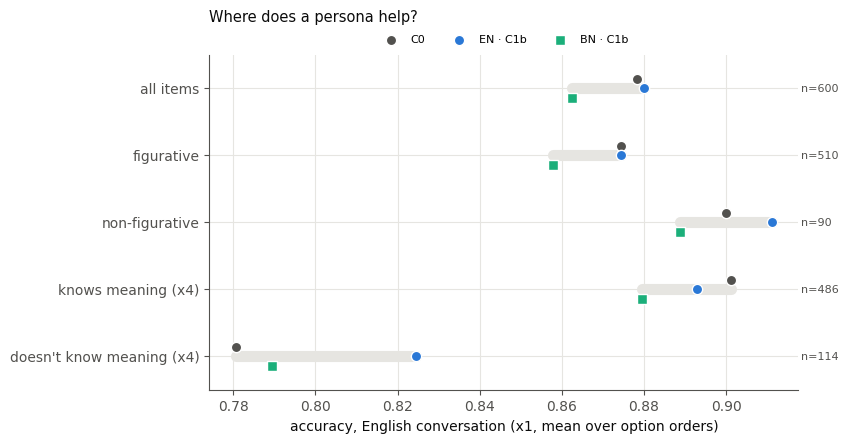

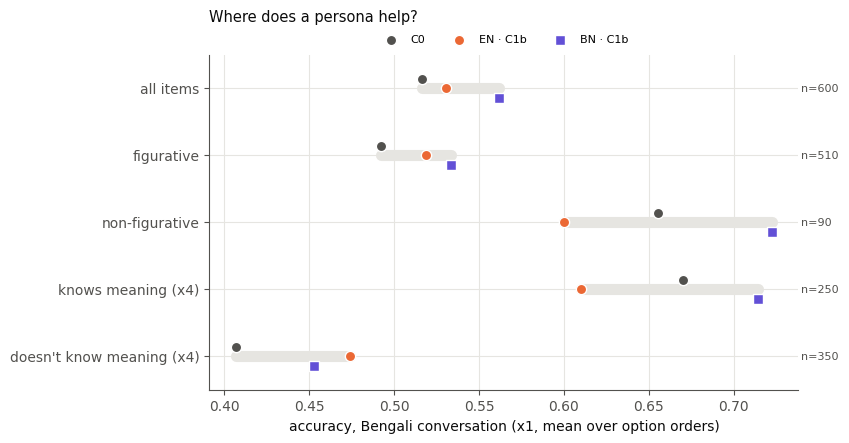

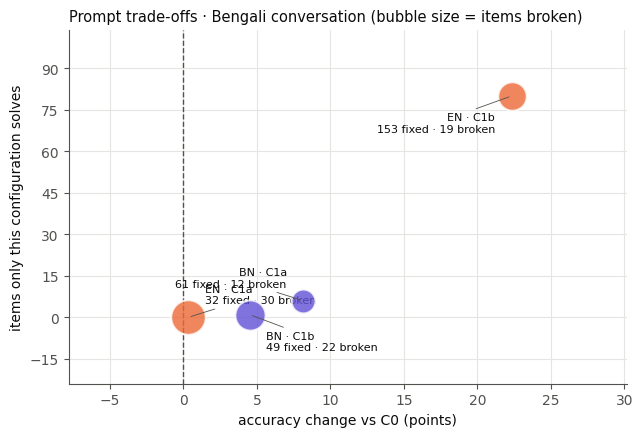

,condition,gain_pts,fixed,broken,unique
0,EN · C1a,0.333333,32,30,0
1,BN · C1b,4.500000,49,22,1
2,BN · C1a,8.166667,61,12,6
3,EN · C1b,22.333333,153,19,80


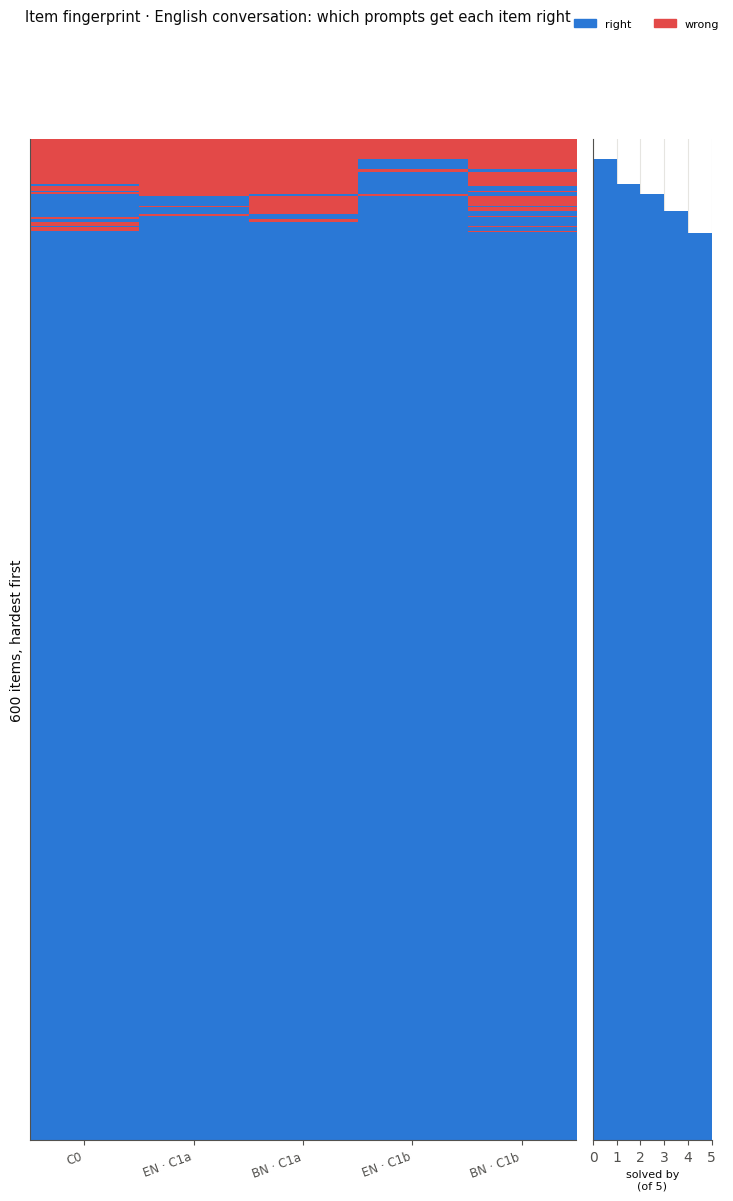

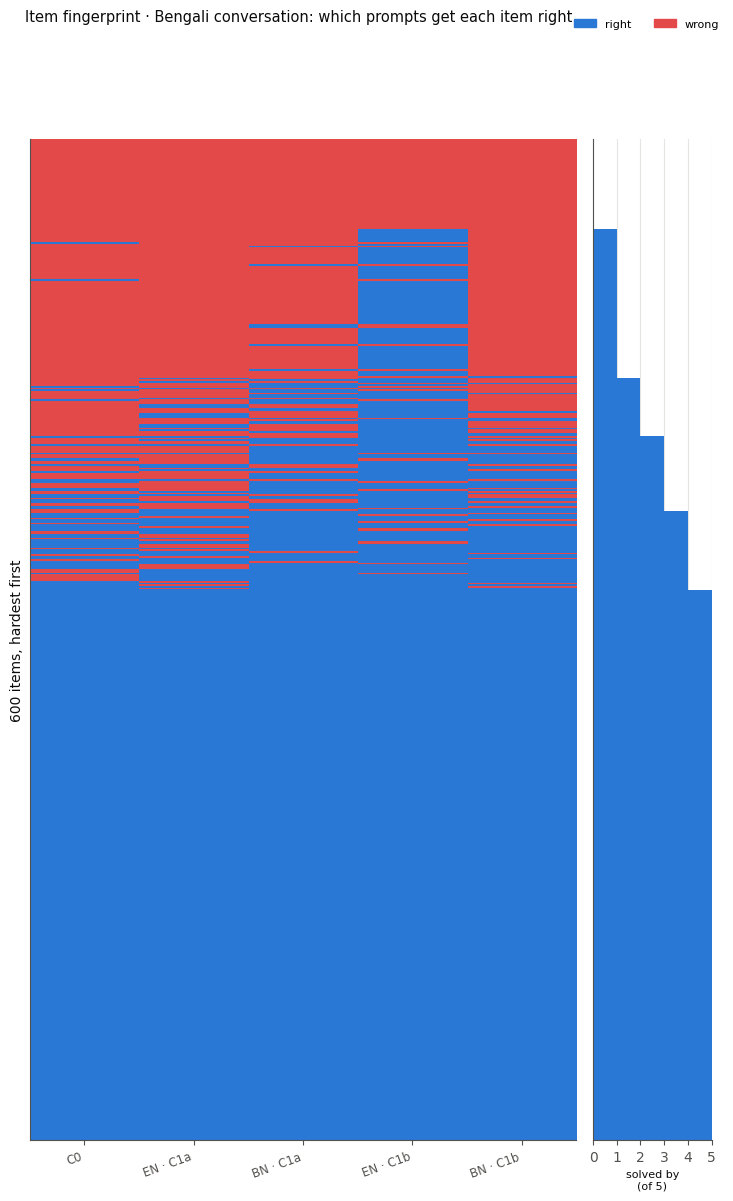

In [25]:
def subgroup_dumbbell(conv, name):
    M = prompt_matrix(conv, METRIC_COL[MAIN])
    if M.shape[1] < 2:
        return
    show = [c for c in M.columns if c == "C0" or not c.endswith("C1a")]      # C0, every C1b, and any extra prompt
    colors = {c: MUTED if c == "C0" else RUN_STYLE[(c.split(" · ")[0].lower(), conv)][0] if c.endswith("C1b")
              else "#eda100" for c in show}
    meta = M.reset_index()
    fig_ = meta["item_id"].map(lambda i: ITEM_BY_ID.get(i, {}).get("proverb", {}).get("figurative"))
    groups = {"all items": np.ones(len(meta), bool), "figurative": (fig_ == True).to_numpy(),
              "non-figurative": (fig_ == False).to_numpy()}
    if has(f"x4_{conv}"):
        kn = item_level(sub(f"x4_{conv}"), ()).set_index("item_id")[METRIC_COL[MAIN]].reindex(meta["item_id"]) >= 0.5
        groups["knows meaning (x4)"] = kn.to_numpy()
        groups["doesn't know meaning (x4)"] = ~kn.to_numpy()
    fig, ax = plt.subplots(figsize=(7.6, 0.55 * len(groups) + 1.6))
    for i, (gname, mask) in enumerate(groups.items()):
        accs = {c: M[c].to_numpy()[mask].mean() for c in show}
        ax.plot([min(accs.values()), max(accs.values())], [i, i], color=GRID, lw=8, zorder=1, solid_capstyle="round")
        for j, c in enumerate(show):
            ax.scatter(accs[c], i + (j - (len(show) - 1) / 2) * 0.14, color=colors[c], s=55, zorder=3,
                       marker="s" if c.startswith("BN") else "o", edgecolors="white", linewidths=1,
                       label=c if i == 0 else None)
        ax.text(1.005, i, f"n={int(mask.sum())}", va="center", fontsize=8, color=MUTED, transform=ax.get_yaxis_transform())
    ax.set_yticks(range(len(groups)), list(groups)); ax.set_ylim(len(groups) - 0.5, -0.5)
    ax.set_xlabel(f"accuracy, {LANG_NAME[conv]} (x1, {METRIC_NAME[MAIN]})")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(show), fontsize=8)
    ax.set_title("Where does a persona help?", pad=24)
    save(fig, name)

def tradeoff_plot(conv, name):
    RT = prompt_matrix(conv, METRIC_COL[MAIN]).dropna() >= 0.5
    sets = [c for c in RT.columns if c != "C0"]
    if "C0" not in RT or not sets:
        return
    base = RT["C0"]
    rows = []
    for c in sets:
        cur = RT[c]
        rows.append({"condition": c, "gain_pts": (cur.mean() - base.mean()) * 100, "fixed": int((~base & cur).sum()),
                     "broken": int((base & ~cur).sum()),
                     "unique": int((cur & ~RT.drop(columns=c).any(axis=1)).sum())})
    tr = pd.DataFrame(rows).sort_values(["unique", "gain_pts"]).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    offsets = [(12, 10), (12, -26), (-12, 10), (-12, -26)]
    for k, r in tr.iterrows():
        pl = r["condition"].split(" · ")[0].lower()
        col, mk = RUN_STYLE.get((pl, conv), ("#eda100", "o"))
        ax.scatter(r["gain_pts"], r["unique"], s=80 + 18 * r["broken"], color=col, alpha=0.8,
                   edgecolors="white", linewidths=1.5, zorder=3)
        dx, dy = offsets[k % len(offsets)]
        ax.annotate(f"{r['condition']}\n{r['fixed']} fixed · {r['broken']} broken", (r["gain_pts"], r["unique"]),
                    xytext=(dx, dy), textcoords="offset points", fontsize=8, color=INK, ha="left" if dx > 0 else "right",
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.axvline(0, color=MUTED, ls="--", lw=1)
    ax.set_xlabel("accuracy change vs C0 (points)"); ax.set_ylabel("items only this configuration solves")
    ax.set_title(f"Prompt trade-offs · {LANG_NAME[conv]} (bubble size = items broken)")
    ax.margins(x=0.35, y=0.3)
    save(fig, name)
    display(tr)

def fingerprint_plot(conv, name):
    RT = prompt_matrix(conv, METRIC_COL[MAIN])
    if RT.shape[1] < 2:
        return
    B = (RT >= 0.5).astype(float).where(RT.notna())
    B = B.loc[B.mean(axis=1).sort_values(kind="stable").index]
    n, k = B.shape
    fig = plt.figure(figsize=(8.8, max(5, min(13, n * 0.02 + 3))))
    gs = fig.add_gridspec(1, 2, width_ratios=[6, 1.3], wspace=0.05)
    ax, side = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
    data = np.where(np.isnan(B.to_numpy()), 1, B.to_numpy() * 2)
    ax.imshow(data, aspect="auto", interpolation="nearest",
              cmap=ListedColormap([LOSS, "#d8d8d8", "#2a78d6"]), norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3))
    ax.set_xticks(range(k), B.columns, fontsize=8.5, rotation=20, ha="right")
    ax.set_yticks([]); ax.grid(False)
    ax.set_ylabel(f"{n} items, hardest first")
    solved = np.nansum(B.to_numpy(), axis=1)
    side.barh(np.arange(n), solved, height=1.0, color="#2a78d6")
    side.set_ylim(n - 0.5, -0.5); side.set_xlim(0, k); side.set_yticks([]); side.set_xticks(range(k + 1))
    side.set_xlabel(f"solved by\n(of {k})", fontsize=8)
    fig.legend(handles=[Patch(color="#2a78d6", label="right"), Patch(color=LOSS, label="wrong")],
               loc="upper right", bbox_to_anchor=(0.92, 0.98), ncol=2, fontsize=8)
    fig.suptitle(f"Item fingerprint · {LANG_NAME[conv]}: which prompts get each item right",
                 x=0.12, ha="left", fontsize=10.5, color=INK, y=0.98)
    save(fig, name)

if not X8.empty:
    for cv in LANGS:
        subgroup_dumbbell(cv, f"F6_where_persona_helps_{cv}")
    tradeoff_plot("bn" if "bn" in LANGS else LANGS[0], "F7_prompt_tradeoffs")
    for cv in LANGS:
        fingerprint_plot(cv, f"F8_item_fingerprint_{cv}")

### F9 · How many items are needed to tell two prompts apart?
This is a power check: the ±95% CI of a prompt difference for different numbers of items, using the observed x8 differences on Bengali conversations. A difference is detectable where its dashed line sits above the curve. The curve is useful for sizing any later prompt-optimisation run.

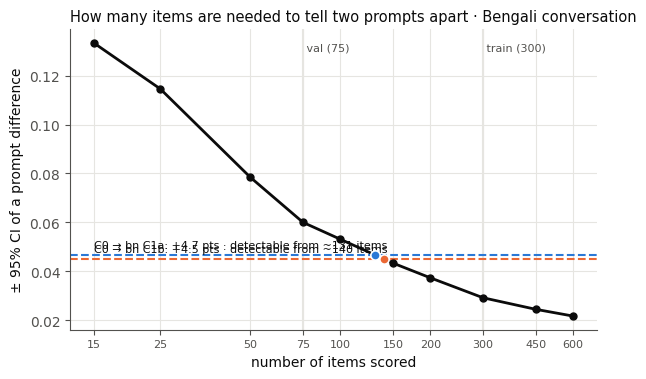

In [26]:
def eval_budget(conv, name):
    if PT.empty or "diff_vs_C0" not in PT:
        return
    t = PT[(PT["conv"] == conv) & PT["diff_vs_C0"].notna()].copy()
    if t.empty:
        return
    t["abs"] = t["diff_vs_C0"].abs()
    t = t.sort_values("abs", ascending=False).head(2)
    big = t.iloc[0]
    d = (item_level(x8_rows(conv, big["prompt_lang"], big["cond"]), ()).set_index("item_id")[METRIC_COL[MAIN]]
         - item_level(x8_rows(conv, None, "C0"), ()).set_index("item_id")[METRIC_COL[MAIN]]).dropna()
    prov = pd.Series({i: ITEM_BY_ID[i]["proverb"]["proverb_id"] for i in d.index})
    _, inv = np.unique(prov.to_numpy(), return_inverse=True)
    s, c = np.bincount(inv, d.to_numpy()), np.bincount(inv)
    per = len(d) / len(c)
    rng = np.random.default_rng(0)
    ns = [n for n in (15, 25, 50, 75, 100, 150, 200, 300, 450, 600, 900) if n <= len(d)]
    if len(ns) < 2:
        print(f"F9 needs at least 25 items (have {len(d)})"); return
    half = []
    for n in ns:
        pick = rng.integers(0, len(c), (2000, max(2, round(n / per))))
        b = s[pick].sum(1) / c[pick].sum(1)
        half.append((np.percentile(b, 97.5) - np.percentile(b, 2.5)) / 2)
    fig, ax = plt.subplots(figsize=(6.8, 3.9))
    ax.plot(ns, half, color=INK, lw=2, marker="o", ms=5, zorder=3)
    for (_, r), col in zip(t.iterrows(), [GAIN, "#eb6834"]):
        e = abs(r["diff_vs_C0"])
        ax.axhline(e, color=col, lw=1.5, ls="--", zorder=2)
        below = [i for i, h in enumerate(half) if h < e]
        if below:
            i = below[0]
            n_star = ns[0] if i == 0 else np.exp(np.interp(e, [half[i], half[i - 1]], [np.log(ns[i]), np.log(ns[i - 1])]))
            ax.scatter(n_star, e, color=col, s=45, zorder=4, edgecolors="white", linewidths=1.2)
            note = f"detectable from ~{n_star:.0f} items"
        else:
            note = f"not detectable with {ns[-1]} items"
        left = abs(half[0] - e) > abs(half[-1] - e)
        ax.text(ns[0] if left else ns[-1], e + 0.002,
                f"C0 → {r['prompt_lang']} {r['cond']}: {r['diff_vs_C0'] * 100:+.1f} pts · {note}",
                color=INK, fontsize=8, ha="left" if left else "right", va="bottom")
    for n, nm in [(75, "val (75)"), (300, "train (300)")]:
        if ns[0] <= n <= ns[-1]:
            ax.axvline(n, color=GRID, lw=1.5, zorder=1)
            ax.text(n, max(half), f" {nm}", fontsize=8, color=MUTED, va="top")
    ax.set_xscale("log"); ax.set_xticks(ns, [str(n) for n in ns], fontsize=8); ax.minorticks_off()
    ax.set_xlabel("number of items scored"); ax.set_ylabel("± 95% CI of a prompt difference")
    ax.set_title(f"How many items are needed to tell two prompts apart · {LANG_NAME[conv]}")
    save(fig, name)

eval_budget("bn" if "bn" in LANGS else LANGS[0], "F9_eval_budget")

## G. False friends (x9)
Depricated

## H. Diagnostics
- **H1:** letter mass by condition. It should be well above 0.05; very low values mean the model was not answering with a letter.
- **H2:** calibration. The confidence of the chosen option vs how often it is right, with expected calibration error (ECE). *Your calibration plot, fixed.* It previously compared P(gold) with correctness, but with one option order correctness is decided by P(gold) itself, so that curve couldn't be meaningful.
- **H3:** how often the gold answer sits at each letter. It should be balanced once swaps are on.

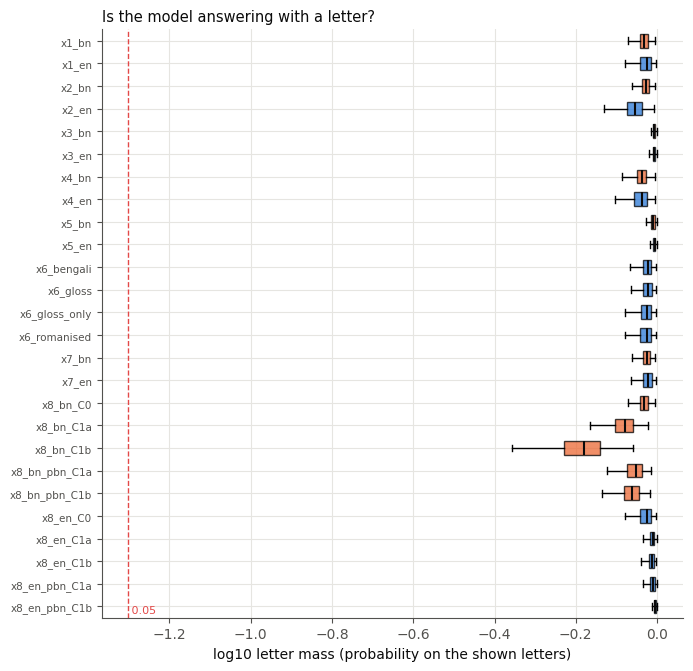

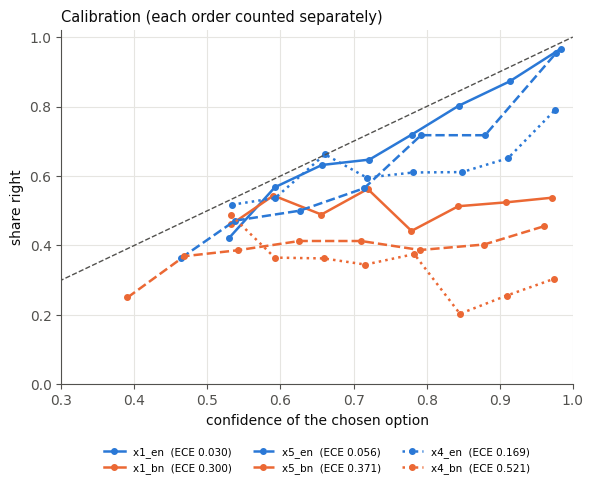

,label,ECE,mean_conf,acc
0,x1_en,0.030,0.908,0.878
1,x1_bn,0.300,0.817,0.517
2,x5_en,0.056,0.893,0.837
3,x5_bn,0.371,0.784,0.413
4,x4_en,0.169,0.858,0.689
5,x4_bn,0.521,0.836,0.316


gold,gold_at_a,gold_at_b,gold_at_c
label,,,
x1_bn,0.50,0.50,0.00
x1_en,0.50,0.50,0.00
x2_bn,0.50,0.50,0.00
x2_en,0.50,0.50,0.00
x3_bn,0.00,0.00,1.00
x3_en,0.00,0.00,1.00
x4_bn,0.50,0.50,0.00
x4_en,0.50,0.50,0.00
x5_bn,0.33,0.33,0.33


In [27]:
def mass_plot(name):
    labs = OV["label"].tolist()
    data = [np.log10(sub(l)["letter_mass"].clip(lower=1e-12)) for l in labs]
    fig, ax = plt.subplots(figsize=(7.5, 0.24 * len(labs) + 1.4))
    bp = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, lw=1.5))
    for patch, l in zip(bp["boxes"], labs):
        patch.set_facecolor(LANG_COLOR.get(sub(l)["conv_lang"].iat[0], "#2a78d6")); patch.set_alpha(0.75)
    ax.axvline(np.log10(0.05), color=LOSS, ls="--", lw=1)
    ax.text(np.log10(0.05), len(labs) + 0.4, " 0.05", color=LOSS, fontsize=8, va="bottom")
    ax.set_yticks(range(1, len(labs) + 1), labs, fontsize=7.5); ax.set_ylim(len(labs) + 0.5, 0.5)
    ax.set_xlabel("log10 letter mass (probability on the shown letters)")
    ax.set_title("Is the model answering with a letter?")
    save(fig, name)

def calibration_plot(labels, name, bins=8, min_n=10):
    rows = []
    fig, ax = plt.subplots(figsize=(6.6, 4.6))
    styles = {"x1": "-", "x5": "--", "x4": ":"}
    for lab in labels:
        if not has(lab):
            continue
        d = sub(lab)
        conf = d[["p_a", "p_b", "p_c"]].max(axis=1)
        k = d["n_opts"].iat[0]
        edges = np.linspace(1 / k, 1, bins + 1)
        b = pd.cut(conf, edges, include_lowest=True)
        g = pd.DataFrame({"conf": conf, "ok": d["correct"], "b": b}).groupby("b", observed=True).agg(
            conf=("conf", "mean"), acc=("ok", "mean"), n=("ok", "size"))
        ece = float((g["n"] / g["n"].sum() * (g["acc"] - g["conf"]).abs()).sum())
        g = g[g["n"] >= min_n]                     # sparse bins are noise: drawn only with >= min_n answers
        lang = d["conv_lang"].iat[0]
        ax.plot(g["conf"], g["acc"], marker="o", ms=4, lw=1.8, color=LANG_COLOR.get(lang, INK),
                ls=styles.get(lab.split("_")[0], "-"), label=f"{lab}  (ECE {ece:.3f})")
        rows.append({"label": lab, "ECE": ece, "mean_conf": conf.mean(), "acc": d["correct"].mean()})
    ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
    ax.set_xlim(0.3, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel("confidence of the chosen option"); ax.set_ylabel("share right")
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
    ax.set_title("Calibration (each order counted separately)")
    save(fig, name)
    return pd.DataFrame(rows)

mass_plot("H1_letter_mass")
CAL = calibration_plot([f"{e}_{l}" for e in ("x1", "x5", "x4") for l in LANGS], "H2_calibration")
display(CAL.round(3))
bal = R.groupby("label")["gold"].value_counts(normalize=True).unstack().fillna(0).add_prefix("gold_at_")
display(bal.round(2))

## I. Error export
Items the model gets wrong in **every** order, with the proverb, meaning, conversation, options and what it picked in each order. One CSV per condition goes to `tables/errors_<label>.csv`, for manual error analysis and the paper's examples.

In [30]:
def error_table(label):
    d = sub(label)
    if d.empty:
        return pd.DataFrame()
    it = item_level(d, ())
    bad = it[it["correct"] == 0]["item_id"]                 # mean over orders = 0  ->  wrong in every order
    picks = d.groupby("item_id")["pred_key"].agg(lambda s: " / ".join(s))
    rows = []
    for i in bad:
        item = ITEM_BY_ID.get(i)
        if item is None:
            continue
        lang = d[d["item_id"] == i]["conv_lang"].iat[0]
        o = item[lang]["options"]
        rows.append({"item_id": i, "proverb_bn": item["proverb"]["bengali"], "romanised": item["proverb"]["romanised"],
                     "meaning_en": item["proverb"]["meaning"].get("en"), "figurative": item["proverb"].get("figurative"),
                     "conversation": "\n".join(f"{t['speaker']}: {t['text']}" for t in item[lang]["turns"]),
                     "correct": o.get("correct"), "literal": o.get("literal"), "plausible": o.get("plausible"),
                     "model_picked (per order)": picks.get(i)})
    out = pd.DataFrame(rows)
    out.to_csv(TAB / f"errors_{label}.csv", index=False)
    return out

for lab in ["x1_bn", "x1_en", "x5_bn", "x2_bn", "x4_bn"]:
    if has(lab):
        e = error_table(lab)
        print(f"{lab}: {len(e)} items wrong in every order -> tables/errors_{lab}.csv")
display(error_table("x1_bn").head(5) if has("x1_bn") else None)

x1_bn: 216 items wrong in every order -> tables/errors_x1_bn.csv
x1_en: 36 items wrong in every order -> tables/errors_x1_en.csv
x5_bn: 237 items wrong in every order -> tables/errors_x5_bn.csv
x2_bn: 290 items wrong in every order -> tables/errors_x2_bn.csv
x4_bn: 350 items wrong in every order -> tables/errors_x4_bn.csv


,item_id,proverb_bn,romanised,meaning_en,figurative,conversation,correct,literal,plausible,model_picked (per order)
0,prv_002_3,অল্প বিদ্যা ভয়ংকরী,Olpo bidya bhoyonkori.,A little knowledge is a dangerous thing: half-...,False,স্নেহা: নতুন ইন্টার্ন দু'সপ্তাহের কোডিং কোর্স ...,সামান্য শিখেই অতিরিক্ত আত্মবিশ্বাসে ইন্টার্ন ও...,অল্পস্বল্প পড়াশোনা জানা থাকাটা আসলে একটা ভীতি...,"ইন্টার্ন প্রতিভাবান, সাইট বন্ধ হওয়াটা নেহাত দ...",literal / literal
1,prv_004_2,অভাবে স্বভাব নষ্ট,Obhabe shobhab noshto.,Poverty and need can make an honest person do ...,False,অঞ্জলি: রাজু তো ক্লাসে প্রথম হত। এখন দেখি পাড়...,চরম দারিদ্র্যই রাজুর মতো ভালো ছেলেকে খারাপ সঙ্...,"যেখানে জিনিসপত্রের টানাটানি, সেখানে প্রকৃতির র...","রাজু বরাবরই বখাটে ছিল, এখন শুধু ওর আসল রূপ বের...",literal / literal
2,prv_004_3,অভাবে স্বভাব নষ্ট,Obhabe shobhab noshto.,Poverty and need can make an honest person do ...,False,পার্থ: আমাদের অফিসের সবচেয়ে সৎ মানুষ বিজনদা এ...,হাসপাতালের বিশাল খরচের চাপে বিজনদার মতো সৎ মান...,কোনো কিছুর অভাব ঘটলে প্রাকৃতিক পরিবেশের ক্ষতি ...,বিজনদা এত বছর ধরে শুধু সৎ হওয়ার ভান করে এসেছেন।,literal / literal
3,prv_005_1,আপনি বাঁচলে বাপের নাম,Apni banchle baper nam.,Look after yourself first; everything else com...,True,তন্ময়: অর্ণব আবার ওর প্রজেক্টের অংশটা আমার ঘা...,অর্ণবের কাজ সামলানোর আগে তন্ময়ের নিজের শরীরের...,ছেলে বেঁচে থাকলে তবেই বাবার নামটা এই পৃথিবীতে ...,"শরীরের চেয়ে বন্ধুত্ব বড়, তাই তন্ময়ের অর্ণবক...",literal / literal
4,prv_005_2,আপনি বাঁচলে বাপের নাম,Apni banchle baper nam.,Look after yourself first; everything else com...,True,কালু: আমি আরেকবার ঢুকে টিভি আর ফ্রিজটা নিয়ে আ...,জিনিসপত্রের চেয়ে কালুর নিজের প্রাণ বাঁচানো অন...,নিজে টিকে থাকলে তবেই পিতার পরিচয় বজায় থাকে।,"টিভি আর ফ্রিজ অনেক দামি, তাই কালুর সেগুলো বাঁচ...",literal / literal


## J. Key numbers for the write-up

In [29]:
def kn(label, col=MAIN):
    v = get_ov(OV, label, col)
    return np.nan if v is None else v

lines = [f"**Model:** `{R['model'].iat[0]}` · metric: {METRIC_NAME[MAIN]} · {R['item_id'].nunique()} items"]
if KU and len(LANGS) == 2:
    gk, gu = KU["en"][0] - KU["bn"][0], KU["en"][1] - KU["bn"][1]
    lines.append(f"- **Knowing vs using:** x4 en {KU['en'][0]:.3f} / bn {KU['bn'][0]:.3f} (gap {gk * 100:.1f} pts); "
                 f"x1 en {KU['en'][1]:.3f} / bn {KU['bn'][1]:.3f} (gap {gu * 100:.1f} pts)"
                 + (f"; the conversation closes {1 - gu / gk:.0%} of the gap" if gk > 0 and gu <= gk else ""))
for l in LANGS:
    if has(f"x1_{l}", f"x2_{l}"):
        lines.append(f"- **Question following ({l}):** asked meaning {kn(f'x1_{l}'):.3f} · asked NOT {kn(f'x2_{l}'):.3f}"
                     + (f" · no question {kn(f'x7_{l}'):.3f}" if has(f"x7_{l}") else "")
                     + (f" · none-of-these {kn(f'x3_{l}'):.3f}" if has(f"x3_{l}") else ""))
if has("x5_en") or has("x5_bn"):
    lines.append("- **3 options (x5):** " + " · ".join(f"{l} {kn(f'x5_{l}'):.3f}" for l in LANGS if has(f"x5_{l}")))
if not PT.empty and "diff_vs_C0" in PT:
    for _, r in PT[PT["diff_vs_C0"].notna()].iterrows():
        lines.append(f"- **Persona {r['prompt_lang']} {r['cond']} on {r['conv']} conversations:** "
                     f"{r['diff_vs_C0'] * 100:+.1f} pts [{r['diff_lo'] * 100:+.1f}, {r['diff_hi'] * 100:+.1f}]")
for l in LANGS:
    g = OVL[OVL["lang"] == l]
    if len(g):
        lines.append(f"- **Word-overlap shortcut ({l}):** correct vs literal {g['correct vs literal'].mean():.3f}, "
                     f"correct vs plausible {g['correct vs plausible'].mean():.3f}")
ov_o = OV[OV["orders"] > 1]
if len(ov_o):
    lines.append(f"- **Order robustness:** same answer in every order for {ov_o['consistent'].mean():.0%} of items on average "
                 f"(lowest: {ov_o.sort_values('consistent').iloc[0]['label']} {ov_o['consistent'].min():.0%})")
KEY_NUMBERS = "\n".join(lines)
(TAB / "key_numbers.md").write_text(KEY_NUMBERS, encoding="utf-8")
display(Markdown(KEY_NUMBERS))

**Model:** `Qwen/Qwen2.5-1.5B-Instruct` · metric: mean over option orders · 600 items
- **Knowing vs using:** x4 en 0.689 / bn 0.316 (gap 37.3 pts); x1 en 0.878 / bn 0.517 (gap 36.2 pts); the conversation closes 3% of the gap
- **Question following (en):** asked meaning 0.878 · asked NOT 0.699 · no question 0.909 · none-of-these 0.212
- **Question following (bn):** asked meaning 0.517 · asked NOT 0.384 · no question 0.688 · none-of-these 0.590
- **3 options (x5):** en 0.837 · bn 0.413
- **Persona en C1a on en conversations:** -0.5 pts [-1.9, +0.8]
- **Persona en C1b on en conversations:** +0.2 pts [-1.6, +1.8]
- **Persona bn C1a on en conversations:** -1.6 pts [-2.8, -0.3]
- **Persona bn C1b on en conversations:** -1.6 pts [-3.1, -0.1]
- **Persona en C1a on bn conversations:** -2.7 pts [-4.6, -0.8]
- **Persona en C1b on bn conversations:** +1.4 pts [-1.9, +4.6]
- **Persona bn C1a on bn conversations:** +4.7 pts [+2.6, +6.8]
- **Persona bn C1b on bn conversations:** +4.5 pts [+2.2, +7.0]
- **Word-overlap shortcut (en):** correct vs literal 0.757, correct vs plausible 0.289
- **Word-overlap shortcut (bn):** correct vs literal 0.670, correct vs plausible 0.393
- **Order robustness:** same answer in every order for 77% of items on average (lowest: x8_bn_C1b 34%)

## K. Compare models
This section looks for every run under `RESULTS_ROOT` (and `COMPARE_DIRS`). To compare models run in different Kaggle sessions, attach the earlier runs' output folders as datasets and list them in `COMPARE_DIRS`. It needs at least two runs.

In [ ]:
def discover_runs():
    found = {}
    for d in sorted(RESULTS_ROOT.glob("*/raw")):
        if any(d.glob("*.csv")) and (INCLUDE_SMOKE_RUNS or "_smoke" not in d.parent.name):
            found[d.parent.name] = d
    for p in COMPARE_DIRS:
        p = Path(p)
        p = p / "raw" if (p / "raw").exists() else p
        if p.exists() and any(p.glob("*.csv")):
            found[p.parent.name if p.name == "raw" else p.name] = p
    return found

RUNS_FOUND = discover_runs()
print("runs found:", list(RUNS_FOUND))
CMP = {}
if len(RUNS_FOUND) >= 2:
    for name, d in RUNS_FOUND.items():
        df = R if Path(d).resolve() == RAW.resolve() else load_results(d)
        CMP[name] = {"R": df, "OV": summary(df)}
    pd.concat([v["OV"].assign(run=k) for k, v in CMP.items()]).to_csv(TAB / "K_compare_overview.csv", index=False)
else:
    print("Section K needs at least two runs: nothing to compare yet.")

In [ ]:
def model_heatmap(name):
    cols = [(e, l) for e, _ in BATTERY for l in LANGS if all(get_ov(v["OV"], f"{e}_{l}") is not None for v in CMP.values())]
    if not cols:
        return
    names = list(CMP)
    M = np.array([[get_ov(CMP[n]["OV"], f"{e}_{l}", MAIN) for e, l in cols] for n in names], float)
    chance = [get_ov(CMP[names[0]]["OV"], f"{e}_{l}", "chance") for e, l in cols]
    fig, ax = plt.subplots(figsize=(0.8 * len(cols) + 2.6, 0.62 * len(names) + 2.0))
    cmap = LinearSegmentedColormap.from_list("seq", ["#f4f7fb", "#9cc3ec", "#2a78d6", "#123f7a"])
    ax.imshow(M, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    for i in range(len(names)):
        for j in range(len(cols)):
            v = M[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if v > 0.62 else INK, fontweight="bold" if v < chance[j] else None)
    ax.set_xticks(range(len(cols)), [f"{e} {l}\n(chance {c:.2f})" for (e, l), c in zip(cols, chance)], fontsize=7.5)
    ax.set_yticks(range(len(names)), names, fontsize=8.5)
    ax.grid(False)
    for j in range(1, len(cols)):
        if cols[j][0] != cols[j - 1][0]:
            ax.axvline(j - 0.5, color="white", lw=3)
    ax.set_title(f"Model fingerprint ({METRIC_NAME[MAIN]}; bold = below chance)")
    save(fig, name)

def model_slopes(name):
    langs = [l for l in LANGS if all(get_ov(v["OV"], f"x4_{l}") is not None and get_ov(v["OV"], f"x1_{l}") is not None
                                     for v in CMP.values())]
    if not langs:
        return
    fig, axes = plt.subplots(1, len(langs), figsize=(4.6 * len(langs) + 1.2, 4.2), sharey=True, squeeze=False)
    for ax, l in zip(axes[0], langs):
        for i, (n, v) in enumerate(CMP.items()):
            k, u = get_ov(v["OV"], f"x4_{l}", MAIN), get_ov(v["OV"], f"x1_{l}", MAIN)
            col = MODEL_COLORS[i % len(MODEL_COLORS)]
            ax.plot([0, 1], [k, u], color=col, lw=2.2, marker="o", ms=7)
            ax.text(1.05, u, n, va="center", fontsize=8, color=INK)
        ax.set_xticks([0, 1], ["knowing\n(x4)", "using\n(x1)"]); ax.set_xlim(-0.2, 1.9)
        ax.set_title(LANG_NAME[l]); ax.grid(axis="x", visible=False)
    axes[0, 0].set_ylabel(f"accuracy ({METRIC_NAME[MAIN]})")
    fig.suptitle("Knowing vs using, per model", x=0.01, ha="left", fontsize=10.5, color=INK)
    fig.tight_layout()
    save(fig, name)

def model_persona_forest(name):
    rows = []
    for i, (n, v) in enumerate(CMP.items()):
        df = v["R"]
        x8 = df[df["exp"] == "x8"]
        for cv in LANGS:
            base = x8[(x8["conv_lang"] == cv) & (x8["condition"] == "C0")]
            if base.empty:
                continue
            for (pl, c), g in x8[(x8["conv_lang"] == cv) & (x8["condition"] != "C0")].groupby(["prompt_lang", "condition"]):
                p = paired(base, g)
                rows.append({"run": n, "row": f"{c} · {pl} prompt · {cv} conv", **p})
    if not rows:
        return
    T = pd.DataFrame(rows)
    order = list(dict.fromkeys(T["row"]))
    fig, ax = plt.subplots(figsize=(7.4, 0.5 * len(order) + 1.6))
    names = list(CMP)
    for i, n in enumerate(names):
        t = T[T["run"] == n].set_index("row").reindex(order)
        y = np.arange(len(order)) + (i - (len(names) - 1) / 2) * 0.2
        col = MODEL_COLORS[i % len(MODEL_COLORS)]
        ax.errorbar(t["diff"] * 100, y, xerr=[(t["diff"] - t["ci_lo"]) * 100, (t["ci_hi"] - t["diff"]) * 100],
                    fmt="o", ms=6, color=col, lw=1.8, capsize=0, label=n)
    ax.axvline(0, color=MUTED, ls="--", lw=1)
    ax.set_yticks(range(len(order)), order, fontsize=8); ax.set_ylim(len(order) - 0.5, -0.7)
    ax.set_xlabel("accuracy change vs no system prompt (points, 95% CI)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(names), fontsize=8)
    ax.set_title("Persona prompts across models", pad=22)
    save(fig, name)
    T.to_csv(TAB / "K_persona_effects.csv", index=False)

def model_question(name):
    names = list(CMP)
    langs = [l for l in LANGS if all(((v["R"]["label"] == f"x1_{l}").any() and (v["R"]["label"] == f"x2_{l}").any())
                                     for v in CMP.values())]
    if not langs:
        return
    fig, axes = plt.subplots(1, len(langs), figsize=(4.8 * len(langs) + 0.8, 0.55 * len(names) + 1.8), sharey=True, squeeze=False)
    for ax, l in zip(axes[0], langs):
        for i, n in enumerate(names):
            df = CMP[n]["R"]
            a = item_level(df[df["label"] == f"x1_{l}"], ())["pick_correct"].mean()
            b = item_level(df[df["label"] == f"x2_{l}"], ())["pick_correct"].mean()
            col = MODEL_COLORS[i % len(MODEL_COLORS)]
            ax.plot([b, a], [i, i], color=col, lw=2.5, alpha=0.5)
            ax.scatter(a, i, s=60, color=col, zorder=3)
            ax.scatter(b, i, s=60, facecolor="white", edgecolor=col, lw=2, zorder=3)
        ax.set_yticks(range(len(names)), names, fontsize=8.5); ax.set_ylim(len(names) - 0.5, -0.5)
        ax.set_xlim(0, 1.02); ax.set_title(LANG_NAME[l])
        ax.set_xlabel("share picking the figurative meaning")
    handles = [Line2D([], [], marker="o", ls="", color=INK, label="asked: what does it mean? (x1)"),
               Line2D([], [], marker="o", ls="", mfc="white", mec=INK, label="asked: what does it NOT mean? (x2)")]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.06), ncol=2, fontsize=8)
    fig.suptitle("Question following per model: a model that reads the question puts the two dots far apart",
                 x=0.01, ha="left", y=1.12, fontsize=10.5, color=INK)
    fig.tight_layout()
    save(fig, name)

if len(CMP) >= 2:
    model_heatmap("K1_model_fingerprint")
    model_slopes("K2_knowing_vs_using_models")
    model_persona_forest("K3_persona_across_models")
    model_question("K4_question_following_models")

In [41]:
!zip -r /kaggle/working/results-Qwen2.5-1.5B-Instruct.zip /kaggle/working/Qwen2.5-1.5B-Instruct

  adding: kaggle/working/Qwen2.5-1.5B-Instruct/ (stored 0%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/ (stored 0%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/F4_confidence_migration_en.png (deflated 5%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/C1_question_following.png (deflated 16%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/F6_where_persona_helps_bn.png (deflated 15%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/A1_battery.png (deflated 13%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/F9_eval_budget.png (deflated 11%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/A2_order_robustness.png (deflated 16%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/D2_x5_triangle.png (deflated 6%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/F3_fixed_broken.png (deflated 19%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/F8_item_fingerprint_en.png (deflated 34%)
  adding: kaggle/working/Qwen2.5-1.5B-Instruct/figs/F8_item_fin

In [42]:
ls

bn-proverbs-in-context/  results-Qwen2.5-1.5B-Instruct.zip
Qwen2.5-1.5B-Instruct/


In [43]:
from IPython.display import FileLink
FileLink(r'/kaggle/working/results-Qwen2.5-1.5B-Instruct.zip')

/kaggle/working/results-Qwen2.5-1.5B-Instruct.zip

In [44]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/results-Qwen2.5-1.5B-Instruct.zip"))

/kaggle/working/results-Qwen2.5-1.5B-Instruct.zip

In [45]:
import os

zip_path = "/kaggle/working/results-Qwen2.5-1.5B-Instruct.zip"

print("Exists:", os.path.exists(zip_path))
print("Size:", os.path.getsize(zip_path) if os.path.exists(zip_path) else "Missing")

Exists: True
Size: 4751694


In [47]:
from IPython.display import HTML, display

display(HTML("""
<a href="/kaggle/working/results-Qwen2.5-1.5B-Instruct.zip" download>
    Click here to download results.zip
</a>
"""))

In [48]:
ls

bn-proverbs-in-context/  results-Qwen2.5-1.5B-Instruct.zip
Qwen2.5-1.5B-Instruct/
